#IMPORT LIBRARIES & MOUNT DRIVE

In [1]:
import os
import glob
import re
import warnings

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

# Tree models
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor

# Deep learning for images
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array

import matplotlib.pyplot as plt

from google.colab import drive

warnings.filterwarnings("ignore")

# --- Mount Google Drive ---
print("Mounting Google Drive...")
drive.mount("/content/drive")

# --- BASE PATHS (adjust only if your folder name changes) ---
BASE_PATH = "/content/drive/MyDrive/MA981-7-FY : Dissertation/" \
            "cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/" \
            "CGMacros_dateshifted365/CGMacros"

bio_file_path        = os.path.join(BASE_PATH, "bio.csv")
gut_health_file_path = os.path.join(BASE_PATH, "gut_health_test.csv")
microbes_file_path   = os.path.join(BASE_PATH, "microbes.csv")

participant_folder_pattern = os.path.join(BASE_PATH, "CGMacros-*")

print("BASE_PATH:", BASE_PATH)


Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE_PATH: /content/drive/MyDrive/MA981-7-FY : Dissertation/cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/CGMacros_dateshifted365/CGMacros


#PATH SETUP — DEFINE participant_dirs FOR ALL CGMacros-XXX FOLDERS

In [2]:
import os
import pandas as pd
import numpy as np

# Your base dataset path (based on your screenshots)
BASE_PATH = "/content/drive/MyDrive/MA981-7-FY : Dissertation/cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/CGMacros_dateshifted365/CGMacros"

print("Base path:", BASE_PATH)

# Find all participant folders: CGMacros-001, CGMacros-002, ..., CGMacros-049
participant_dirs = sorted([
    d for d in os.listdir(BASE_PATH)
    if os.path.isdir(os.path.join(BASE_PATH, d)) and d.startswith("CGMacros-")
])

print(f"FOUND {len(participant_dirs)} participants:")
print(participant_dirs[:10], " ...")   # show first 10 only


Base path: /content/drive/MyDrive/MA981-7-FY : Dissertation/cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/CGMacros_dateshifted365/CGMacros
FOUND 45 participants:
['CGMacros-001', 'CGMacros-002', 'CGMacros-003', 'CGMacros-004', 'CGMacros-005', 'CGMacros-006', 'CGMacros-007', 'CGMacros-008', 'CGMacros-009', 'CGMacros-010']  ...


#LOAD & MERGE ALL PARTICIPANT DATA, BIO, BASIC PREPROCESSING

In [3]:
import os
import re
import pandas as pd
import numpy as np

print("\n================ LOADING PARTICIPANT CSVs ================\n")

all_dfs = []

for folder in participant_dirs:
    # folder: e.g. 'CGMacros-043'
    csv_name = f"{folder}.csv"                     # 'CGMacros-043.csv'
    csv_path = os.path.join(BASE_PATH, folder, csv_name)

    if not os.path.exists(csv_path):
        print(f"CSV not found for {folder}: {csv_path}")
        continue

    try:
        df = pd.read_csv(csv_path)
        # participant_id = integer from folder name, e.g. 43
        pid_int = int(re.findall(r"\d+", folder)[0])
        df["participant_id"] = pid_int
        all_dfs.append(df)
        print(f"Loaded {folder}: {df.shape}")
    except Exception as e:
        print(f"Error loading {csv_path}: {e}")

if not all_dfs:
    raise RuntimeError("No participant CSVs loaded. Check BASE_PATH and folder structure.")

full_df = pd.concat(all_dfs, ignore_index=True)
print("\nMerged full_df shape:", full_df.shape)

print("\nColumns in full_df (first 40):")
print(full_df.columns.tolist()[:40])

# MERGE BIO DATA


print("\n================ MERGING BIO DATA ================\n")

bio_path = os.path.join(BASE_PATH, "bio.csv")
bio_df = pd.read_csv(bio_path)

# Standardise id column name
if "subject" in bio_df.columns:
    bio_df.rename(columns={"subject": "participant_id"}, inplace=True)

# Ensure participant_id is int in both
full_df["participant_id"] = full_df["participant_id"].astype(int)
bio_df["participant_id"]  = bio_df["participant_id"].astype(int)

full_df = full_df.merge(bio_df, on="participant_id", how="left")

print("After bio merge, shape:", full_df.shape)


# TIME FEATURES

print("\n--- Creating time features ---")

# Your time column is 'Timestamp' (capital T) in CGMacros
if "Timestamp" not in full_df.columns:
    raise ValueError("Expected a 'Timestamp' column in full_df but did not find it.")

full_df["Timestamp"] = pd.to_datetime(full_df["Timestamp"], errors="coerce")

full_df = full_df.sort_values(["participant_id", "Timestamp"]).reset_index(drop=True)

full_df["hour"]      = full_df["Timestamp"].dt.hour
full_df["minute"]    = full_df["Timestamp"].dt.minute
full_df["dayofweek"] = full_df["Timestamp"].dt.dayofweek
full_df["is_weekend"] = full_df["dayofweek"].isin([5, 6]).astype(int)

full_df["hour_sin"] = np.sin(2 * np.pi * full_df["hour"] / 24)
full_df["hour_cos"] = np.cos(2 * np.pi * full_df["hour"] / 24)


# INTERPOLATE GLUCOSE (FIXED WITH transform, NOT apply)

print("\n--- Interpolating missing Libre GL within each participant ---")

GL_COL = "Libre GL"
if GL_COL not in full_df.columns:
    raise ValueError(f"Expected '{GL_COL}' column in full_df but did not find it.")

before_missing = full_df[GL_COL].isna().sum()
print(f"Missing {GL_COL} before interpolation:", before_missing)

# IMPORTANT: transform keeps the same index → no error
full_df[GL_COL] = full_df.groupby("participant_id")[GL_COL].transform(
    lambda s: s.interpolate(limit=6, limit_direction="both")
)

after_missing = full_df[GL_COL].isna().sum()
print(f"Missing {GL_COL} after interpolation:", after_missing)

# Optionally drop rows where Timestamp or Libre GL is still NaN
full_df = full_df.dropna(subset=["Timestamp", GL_COL]).reset_index(drop=True)

print("\nFinal full_df shape after cleaning:", full_df.shape)

print("\nSample rows:")
display(full_df.head())
print("\n================ CELL 3 COMPLETE ================")



================ LOADING PARTICIPANT CSVs ================

Loaded CGMacros-001: (14730, 16)
Loaded CGMacros-002: (17025, 16)
Loaded CGMacros-003: (14565, 16)
Loaded CGMacros-004: (14275, 16)
Loaded CGMacros-005: (14460, 16)
Loaded CGMacros-006: (14460, 16)
Loaded CGMacros-007: (5655, 16)
Loaded CGMacros-008: (14760, 15)
Loaded CGMacros-009: (14370, 15)
Loaded CGMacros-010: (16155, 15)
Loaded CGMacros-011: (14805, 15)
Loaded CGMacros-012: (14655, 15)
Loaded CGMacros-013: (15840, 16)
Loaded CGMacros-014: (17250, 15)
Loaded CGMacros-015: (16875, 15)
Loaded CGMacros-016: (16290, 15)
Loaded CGMacros-017: (16185, 15)
Loaded CGMacros-018: (14085, 15)
Loaded CGMacros-019: (14430, 15)
Loaded CGMacros-020: (16260, 15)
Loaded CGMacros-021: (16125, 15)
Loaded CGMacros-022: (17625, 15)
Loaded CGMacros-023: (16185, 15)
Loaded CGMacros-026: (16320, 15)
Loaded CGMacros-027: (14535, 15)
Loaded CGMacros-028: (18735, 14)
Loaded CGMacros-029: (17730, 14)
Loaded CGMacros-030: (15465, 15)
Loaded CGMacros-

,Unnamed: 0,Timestamp,Libre GL,Dexcom GL,HR,Calories (Activity),METs,Meal Type,Calories,Carbs,...,#2 Contour Fingerstick GLU,Time (t).1,#3 Contour Fingerstick GLU,Time (t).2,hour,minute,dayofweek,is_weekend,hour_sin,hour_cos
0,0.0,2020-05-01 10:30:00,84.000000,NaN,56.0,1.0484,10.0,NaN,NaN,NaN,...,73,12:11,81,13:18,10,30,4,0,0.5,-0.866025
1,1.0,2020-05-01 10:31:00,84.133333,NaN,56.0,1.0484,10.0,NaN,NaN,NaN,...,73,12:11,81,13:18,10,31,4,0,0.5,-0.866025
2,2.0,2020-05-01 10:32:00,84.266667,NaN,57.0,1.0484,10.0,NaN,NaN,NaN,...,73,12:11,81,13:18,10,32,4,0,0.5,-0.866025
3,3.0,2020-05-01 10:33:00,84.400000,NaN,54.0,1.0484,10.0,NaN,NaN,NaN,...,73,12:11,81,13:18,10,33,4,0,0.5,-0.866025
4,4.0,2020-05-01 10:34:00,84.533333,NaN,55.0,1.0484,10.0,NaN,NaN,NaN,...,73,12:11,81,13:18,10,34,4,0,0.5,-0.866025



================ CELL 3 COMPLETE ================


#FEATURE ENGINEERING: LAGS, ROLLING FEATURES, DELTAS, MEAL DETECTION

In [4]:
print("\n================ FEATURE ENGINEERING STARTED ================\n")

df = full_df.copy()

# Validate required columns
required_cols = ["Timestamp", "Libre GL", "participant_id"]
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# 4.1 LAG FEATURES (SHORT GLUCOSE HISTORY)

print("\n--- Creating lag features ---")

for lag in [1, 2, 3, 5, 10]:
    df[f"glucose_lag_{lag}"] = df.groupby("participant_id")["Libre GL"].shift(lag)

# 4.2 ROLLING WINDOW FEATURES

print("\n--- Creating rolling-window features ---")

df["glucose_roll_mean_5"] = df.groupby("participant_id")["Libre GL"].rolling(5).mean().reset_index(level=0, drop=True)
df["glucose_roll_std_5"]  = df.groupby("participant_id")["Libre GL"].rolling(5).std().reset_index(level=0, drop=True)

# 4.3 MULTI-HORIZON GLUCOSE DELTAS (TARGETS)

print("\n--- Creating future glucose delta targets (H=1,3,6) ---")

HORIZONS = [1, 3, 6]

for h in HORIZONS:
    df[f"glucose_future_h{h}"] = df.groupby("participant_id")["Libre GL"].shift(-h)
    df[f"glucose_delta_h{h}"] = df[f"glucose_future_h{h}"] - df["Libre GL"]

# drop future_h*
df = df.drop(columns=[f"glucose_future_h{h}" for h in HORIZONS])

# 4.5 MEAL DETECTION LOGIC

print("\n--- Detecting meals from dataset ---")

# Meals have:
# - Meal Type not null
# - or Image path not null
# - or Carb > 0
meal_mask = (
    df["Meal Type"].notna()
    | df["Image path"].notna()
    | (df["Carbs"].fillna(0) > 0)
)

df["is_meal"] = meal_mask.astype(int)

print("Total meal rows detected:", df["is_meal"].sum())

# 4.6 MEAL WINDOW IDENTIFICATION


print("\n--- Creating post-meal windows (0–2 hours) ---")

df = df.sort_values(["participant_id", "Timestamp"])
df = df.reset_index(drop=True)

# Mark each meal with a unique meal_id (within participant)
df["meal_id"] = 0
df["meal_id"] = df.groupby("participant_id")["is_meal"].cumsum()

# Now meal_id increments at every meal timestamp
# Post-meal window: next 120 minutes worth of rows

df["minutes_since_meal"] = df.groupby("participant_id")["Timestamp"].diff().dt.total_seconds() / 60
df["minutes_since_meal"] = df.groupby("participant_id")["minutes_since_meal"].cumsum()

df["in_post_meal_window"] = df["minutes_since_meal"] <= 120

print("\nMeal window annotation completed.")

# Clean dataset by dropping early rows without lags/deltas
drop_cols = [f"glucose_delta_h{h}" for h in HORIZONS] + [f"glucose_lag_{l}" for l in [1,2,3,5,10]]
df = df.dropna(subset=drop_cols).reset_index(drop=True)

print("\nFinal df shape after cleaning:", df.shape)
print("\n================ FEATURE ENGINEERING COMPLETE ================")

cols_to_delete = ["Meal type", "Meal Type", "meal_type", "meal_Type"]

# Store processed for next steps
processed_df = df.copy()

for col in cols_to_delete:
    if col in processed_df.columns:
        print(f"Deleting column: {col}")
        processed_df = processed_df.drop(columns=[col], errors="ignore")



================ FEATURE ENGINEERING STARTED ================


--- Creating lag features ---

--- Creating rolling-window features ---

--- Creating future glucose delta targets (H=1,3,6) ---

--- Detecting meals from dataset ---
Total meal rows detected: 3258

--- Creating post-meal windows (0–2 hours) ---

Meal window annotation completed.

Final df shape after cleaning: (686820, 64)

================ FEATURE ENGINEERING COMPLETE ================
Deleting column: Meal Type


#BEST FEATURE ENCODING PIPELINE (FOR GLUCOSE DELTA & IMAGE MODEL)

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

print("\n================ BEST FEATURE ENCODING SYSTEM STARTED ================\n")

df_enc = processed_df.copy()

# 1. ----- TIMESTAMP → POWERFUL TIME FEATURES -----
df_enc["Timestamp"] = pd.to_datetime(df_enc["Timestamp"], errors="coerce")

df_enc["hour"] = df_enc["Timestamp"].dt.hour                 # circadian rhythm effect
df_enc["minute"] = df_enc["Timestamp"].dt.minute
df_enc["weekday"] = df_enc["Timestamp"].dt.weekday           # Mon-Sun (0–6)
df_enc["is_weekend"] = (df_enc["weekday"] >= 5).astype(int)  # weekend eating pattern

# OPTIONAL but recommended:
df_enc["time_of_day"] = df_enc["hour"] + df_enc["minute"]/60 # continuous time

# 2. ----- DROP RAW STRING COLUMNS THAT SHOULD NEVER BE FEATURES -----
drop_columns = [
    "Timestamp",          # We already extracted useful time features
    "Image path",         # meaninglessly long strings
    "image_full_path",    # file paths are not meaningful
    "folder_path",        # one value per participant, not useful
    "Notes", "Note", "Comment", "Comments",  # if they exist
    "Description", "Event", "Event Type"     # typical free text fields
]

for col in drop_columns:
    if col in df_enc.columns:
        df_enc = df_enc.drop(columns=col, errors="ignore")

# 3. ----- IDENTIFY REMAINING STRING COLUMNS -----
string_cols = df_enc.select_dtypes(include=["object"]).columns.tolist()
print("String columns detected:", string_cols)

# 4. ----- SELECTIVE CATEGORICAL ENCODING -----
# We encode ONLY meaningful low-cardinality columns.
# High-cardinality columns are harmful → drop them safely.

SAFE_MAX_CATEGORIES = 40  # avoid exploding useless categories

for col in string_cols:
    unique_vals = df_enc[col].nunique()

    # Too many unique → drop (not useful for glucose predictions)
    if unique_vals > SAFE_MAX_CATEGORIES:
        print(f"DROPPING column '{col}' (too many unique values: {unique_vals})")
        df_enc = df_enc.drop(columns=[col])
        continue

    # Good categorical variable → encode it
    print(f"Encoding '{col}' with {unique_vals} categories")
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col].astype(str))

# 5. ----- ENSURE ALL FEATURES ARE NUMERIC -----
non_numeric = df_enc.select_dtypes(include=["object"]).columns.tolist()
if len(non_numeric) > 0:
    print("\n⚠ ERROR: Some non-numeric columns still remain!", non_numeric)
else:
    print("\nAll features are now numeric. ✔")

# 6. FINAL OUTPUT
print("\nFinal encoded dataframe shape:", df_enc.shape)
encoded_df = df_enc.copy()

print("\n================ BEST FEATURE ENCODING COMPLETE ================\n")



================ BEST FEATURE ENCODING SYSTEM STARTED ================

String columns detected: ['Gender', 'Self-identify ', 'Collection time PDL (Lab)', 'Time (t)', 'Time (t).1', 'Time (t).2']
Encoding 'Gender' with 2 categories
Encoding 'Self-identify ' with 4 categories
Encoding 'Collection time PDL (Lab)' with 33 categories
Encoding 'Time (t)' with 34 categories
Encoding 'Time (t).1' with 40 categories
Encoding 'Time (t).2' with 38 categories

All features are now numeric. ✔

Final encoded dataframe shape: (686820, 63)

================ BEST FEATURE ENCODING COMPLETE ================



# BUILD FULL IMAGE PATH FROM participant_id & relative CSV path

In [6]:
import os
import numpy as np
import pandas as pd

# processed_df comes from Cell 4
df = processed_df.copy()

def build_full_image_path(row):
    if pd.isna(row["Image path"]):
        return np.nan

    pid = int(row["participant_id"])  # created earlier from folder name
    folder_name = f"CGMacros-{pid:03d}"

    return os.path.join(
        BASE_PATH,
        folder_name,
        str(row["Image path"])
    )

df["image_full_path"] = df.apply(build_full_image_path, axis=1)

print("Number of usable images:", df["image_full_path"].notna().sum())
print(df["image_full_path"].dropna().head())

processed_df = df.copy()


Number of usable images: 3193
223    /content/drive/MyDrive/MA981-7-FY : Dissertati...
253    /content/drive/MyDrive/MA981-7-FY : Dissertati...
608    /content/drive/MyDrive/MA981-7-FY : Dissertati...
617    /content/drive/MyDrive/MA981-7-FY : Dissertati...
625    /content/drive/MyDrive/MA981-7-FY : Dissertati...
Name: image_full_path, dtype: object


# EXTRACT IMAGE EMBEDDINGS (MOBILENETV2)


In [7]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing import image
from tqdm import tqdm
import numpy as np
import pandas as pd

print("\n================ IMAGE EMBEDDING STEP STARTED ================\n")

df = processed_df.copy()

# Filter rows that actually have an image
img_df = df.dropna(subset=["image_full_path"])[
    ["participant_id", "Timestamp", "image_full_path"]
].copy()

print(f"Meal rows with images: {len(img_df)}")
print("\nSample image paths:")
print(img_df.head())

# Load MobileNetV2 backbone
cnn_model = MobileNetV2(weights="imagenet", include_top=False, pooling="avg")
EMB_DIM = cnn_model.output_shape[1]

print(f"\nCNN embedding model loaded. Output dimension = {EMB_DIM}")

# Function to embed one image

def get_image_embedding(path):
    try:
        img = image.load_img(path, target_size=(224, 224))  # <-- FIXED SIZE
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = preprocess_input(img_array)
        emb = cnn_model.predict(img_array, verbose=0)
        return emb.flatten()
    except Exception as e:
        print(f"Image error for: {path} | {e}")
        return np.full(EMB_DIM, np.nan)


# Generate embeddings
all_embeddings = []

paths = img_df["image_full_path"].tolist()

print("\nEmbedding images...\n")

for p in tqdm(paths):
    emb = get_image_embedding(p)
    all_embeddings.append(emb)

all_embeddings = np.array(all_embeddings)
print("\nEmbeddings array shape:", all_embeddings.shape)

# Merge embeddings back
embedding_cols = [f"img_emb_{i}" for i in range(EMB_DIM)]
emb_df = pd.DataFrame(all_embeddings, columns=embedding_cols)

img_df = img_df.reset_index(drop=True)
img_df = pd.concat([img_df, emb_df], axis=1)

print("\nmeal_with_images_df shape:", img_df.shape)
print("\nSample with embeddings:")
display(img_df.head())

# Save globally
meal_with_images_df = img_df.copy()

print("\n================ IMAGE EMBEDDING STEP COMPLETE ================\n")



================ IMAGE EMBEDDING STEP STARTED ================

Meal rows with images: 3193

Sample image paths:
     participant_id           Timestamp  \
223               1 2020-05-01 14:23:00   
253               1 2020-05-01 14:53:00   
608               1 2020-05-01 20:48:00   
617               1 2020-05-01 20:57:00   
625               1 2020-05-01 21:05:00   

                                       image_full_path  
223  /content/drive/MyDrive/MA981-7-FY : Dissertati...  
253  /content/drive/MyDrive/MA981-7-FY : Dissertati...  
608  /content/drive/MyDrive/MA981-7-FY : Dissertati...  
617  /content/drive/MyDrive/MA981-7-FY : Dissertati...  
625  /content/drive/MyDrive/MA981-7-FY : Dissertati...  

CNN embedding model loaded. Output dimension = 1280

Embedding images...



  2%|▏         | 67/3193 [00:12<05:41,  9.16it/s]

Image error for: /content/drive/MyDrive/MA981-7-FY : Dissertation/cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/CGMacros_dateshifted365/CGMacros/CGMacros-001/photos/00000075-PHOTO-2020-5-9-9-48-0.jpg | [Errno 2] No such file or directory: '/content/drive/MyDrive/MA981-7-FY : Dissertation/cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/CGMacros_dateshifted365/CGMacros/CGMacros-001/photos/00000075-PHOTO-2020-5-9-9-48-0.jpg'


  5%|▍         | 151/3193 [00:24<04:17, 11.83it/s]

Image error for: /content/drive/MyDrive/MA981-7-FY : Dissertation/cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/CGMacros_dateshifted365/CGMacros/CGMacros-002/photos/00000082-PHOTO-2019-11-24-11-37-0.jpg | [Errno 2] No such file or directory: '/content/drive/MyDrive/MA981-7-FY : Dissertation/cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/CGMacros_dateshifted365/CGMacros/CGMacros-002/photos/00000082-PHOTO-2019-11-24-11-37-0.jpg'
Image error for: /content/drive/MyDrive/MA981-7-FY : Dissertation/cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/CGMacros_dateshifted365/CGMacros/CGMacros-002/photos/00000083-PHOTO-2019-11-24-12-13-0.jpg | [Errno 2] No such file or directory: '/content/drive/MyDrive/MA981-7-FY : Dissertation/cgmacros-a-scientific-dataset-for-personalized-nutrition-and-diet-monitoring-1.0.0/CGMacros_dateshifted365/CGMacros/CGMacros-002/photos/00000083-PHOTO-2019-11-24-12-13

100%|██████████| 3193/3193 [08:34<00:00,  6.20it/s]



Embeddings array shape: (3193, 1280)

meal_with_images_df shape: (3193, 1283)

Sample with embeddings:


,participant_id,Timestamp,image_full_path,img_emb_0,img_emb_1,img_emb_2,img_emb_3,img_emb_4,img_emb_5,img_emb_6,...,img_emb_1270,img_emb_1271,img_emb_1272,img_emb_1273,img_emb_1274,img_emb_1275,img_emb_1276,img_emb_1277,img_emb_1278,img_emb_1279
0,1,2020-05-01 14:23:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,0.061033,0.140154,0.468846,0.000000,0.375725,0.114158,0.780296,...,0.222626,0.000000,0.292755,2.231678,0.000000,0.543782,1.786990,0.347257,0.590384,0.854890
1,1,2020-05-01 14:53:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,0.166035,1.489766,0.059476,0.000000,0.000000,2.154656,0.000000,...,0.226797,0.136524,0.000000,0.105092,0.025355,0.120260,0.257995,0.530864,0.110018,0.265006
2,1,2020-05-01 20:48:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,0.000000,0.162380,0.091716,0.000000,0.019497,0.693847,0.000000,...,0.000000,0.015833,0.127451,0.218122,0.000000,0.580541,0.000000,0.490924,0.364162,0.100801
3,1,2020-05-01 20:57:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,0.634430,0.000000,0.414525,0.194818,0.207877,0.000000,0.536632,...,1.550227,0.053928,0.444499,0.997641,0.070495,1.647166,1.813930,0.519032,0.627674,0.327162
4,1,2020-05-01 21:05:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,1.454276,0.000000,0.000000,0.000000,0.000000,0.188642,0.020917,...,0.098362,0.000000,0.109370,0.954997,0.000000,0.307674,0.424898,0.159368,1.693349,0.295147



================ IMAGE EMBEDDING STEP COMPLETE ================



In [8]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

# Extract embedding columns from your meal_with_images_df
img_cols = [c for c in meal_with_images_df.columns if c.startswith("img_emb_")]

print("Number of image embedding columns:", len(img_cols))
print("Example columns:", img_cols[:5])

# Extract embedding matrix (N_meals_with_images × 1280)
X_img = meal_with_images_df[img_cols].values.astype(np.float32)

print("Embedding matrix shape BEFORE cleaning:", X_img.shape)


Number of image embedding columns: 1280
Example columns: ['img_emb_0', 'img_emb_1', 'img_emb_2', 'img_emb_3', 'img_emb_4']
Embedding matrix shape BEFORE cleaning: (3193, 1280)


In [9]:
# Replace NaN & Inf with 0 (or column means)
X_img_clean = np.nan_to_num(
    X_img,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Embedding matrix shape AFTER cleaning:", X_img_clean.shape)
print("Any NaNs?", np.isnan(X_img_clean).any())
print("Any Infs?", np.isinf(X_img_clean).any())


Embedding matrix shape AFTER cleaning: (3193, 1280)
Any NaNs? False
Any Infs? False


In [10]:
class EmbeddingDataset(Dataset):
    def __init__(self, X):
        self.X = torch.tensor(X, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.X[idx]   # Autoencoder target = input

dataset = EmbeddingDataset(X_img_clean)
loader = DataLoader(dataset, batch_size=64, shuffle=True)


In [11]:
import torch.nn as nn

LATENT_DIM = 64   # MODIFY: try 32, 16, or 128 as needed

class AutoEncoder(nn.Module):
    def __init__(self, input_dim=1280, latent_dim=LATENT_DIM):
        super().__init__()

        # Encoder network
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )

        # Decoder network
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z)
        return out, z


In [12]:
np.isnan(X_img).sum(), np.isinf(X_img).sum()


(np.int64(3840), np.int64(0))

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = AutoEncoder(input_dim=len(img_cols), latent_dim=LATENT_DIM).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 50
model.train()

for epoch in range(EPOCHS):
    total_loss = 0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        out, _ = model(xb)
        loss = criterion(out, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {total_loss/len(loader):.6f}")


Using device: cpu
Epoch 1/50 - Loss: 0.341278
Epoch 2/50 - Loss: 0.305325
Epoch 3/50 - Loss: 0.276589
Epoch 4/50 - Loss: 0.261331
Epoch 5/50 - Loss: 0.244970
Epoch 6/50 - Loss: 0.231329
Epoch 7/50 - Loss: 0.219033
Epoch 8/50 - Loss: 0.208921
Epoch 9/50 - Loss: 0.201137
Epoch 10/50 - Loss: 0.194604
Epoch 11/50 - Loss: 0.188487
Epoch 12/50 - Loss: 0.183453
Epoch 13/50 - Loss: 0.179281
Epoch 14/50 - Loss: 0.175001
Epoch 15/50 - Loss: 0.171477
Epoch 16/50 - Loss: 0.167638
Epoch 17/50 - Loss: 0.164495
Epoch 18/50 - Loss: 0.161912
Epoch 19/50 - Loss: 0.158825
Epoch 20/50 - Loss: 0.156372
Epoch 21/50 - Loss: 0.153874
Epoch 22/50 - Loss: 0.151218
Epoch 23/50 - Loss: 0.149094
Epoch 24/50 - Loss: 0.147148
Epoch 25/50 - Loss: 0.145021
Epoch 26/50 - Loss: 0.143230
Epoch 27/50 - Loss: 0.141507
Epoch 28/50 - Loss: 0.140008
Epoch 29/50 - Loss: 0.138517
Epoch 30/50 - Loss: 0.137234
Epoch 31/50 - Loss: 0.135592
Epoch 32/50 - Loss: 0.134555
Epoch 33/50 - Loss: 0.132921
Epoch 34/50 - Loss: 0.131766
Epoch

In [14]:
model.eval()

with torch.no_grad():
    latent_vectors = model.encoder(
        torch.tensor(X_img_clean, dtype=torch.float32).to(device)
    ).cpu().numpy()

print("Latent representation shape:", latent_vectors.shape)


Latent representation shape: (3193, 64)


In [15]:
latent_cols = [f"img_latent_{i}" for i in range(LATENT_DIM)]

# Insert new latent columns
for i, col in enumerate(latent_cols):
    meal_with_images_df[col] = latent_vectors[:, i]

# Remove original 1280-D embeddings
meal_with_images_df = meal_with_images_df.drop(columns=img_cols)

print("Updated meal_with_images_df:", meal_with_images_df.shape)
meal_with_images_df.head()


Updated meal_with_images_df: (3193, 67)


,participant_id,Timestamp,image_full_path,img_latent_0,img_latent_1,img_latent_2,img_latent_3,img_latent_4,img_latent_5,img_latent_6,...,img_latent_54,img_latent_55,img_latent_56,img_latent_57,img_latent_58,img_latent_59,img_latent_60,img_latent_61,img_latent_62,img_latent_63
0,1,2020-05-01 14:23:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,-0.444725,0.403159,0.067607,-0.567928,-1.756294,-0.327689,0.849284,...,0.106655,0.495229,-0.349115,1.602754,-0.665021,-0.460539,-0.492631,0.833919,-0.747535,-1.439533
1,1,2020-05-01 14:53:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,-0.690279,2.625412,-0.906479,0.228499,0.597687,-0.302977,1.943380,...,-2.013435,-1.946907,2.094249,-0.000799,-2.183112,-0.513528,0.330891,2.103174,0.495921,-1.204679
2,1,2020-05-01 20:48:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,-0.244753,0.367545,-0.382122,0.221234,-0.387502,-0.469271,0.780553,...,-0.456029,0.052392,0.304771,1.243913,-1.862461,-0.160153,1.508043,1.390662,0.072733,-1.050321
3,1,2020-05-01 20:57:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,-0.711949,1.216990,-1.230574,1.240780,-0.397864,-1.187983,0.303289,...,0.685009,-1.072480,0.046870,-0.703352,1.143801,-1.208043,0.556185,0.229114,-1.262588,2.516953
4,1,2020-05-01 21:05:00,/content/drive/MyDrive/MA981-7-FY : Dissertati...,1.273491,1.377777,-1.273857,-1.779191,-1.863395,0.514955,-0.319643,...,-1.348343,0.089508,0.626393,-0.898631,-1.188034,-1.217472,1.939344,1.612509,-0.028268,0.608833


In [16]:
# Remove embedding cols if they exist
processed_df = processed_df.drop(columns=img_cols, errors="ignore")

# Merge using participant_id + Timestamp (same keys used during embedding)
processed_df = processed_df.merge(
    meal_with_images_df[["participant_id", "Timestamp"] + latent_cols],
    on=["participant_id", "Timestamp"],
    how="left"
)

print("Final processed_df shape:", processed_df.shape)


Final processed_df shape: (686820, 128)


#BUILD MEAL-LEVEL DATASET WITH IMAGE EMBEDDINGS

In [17]:
import numpy as np
import pandas as pd

print("\n================ BUILDING MEAL-LEVEL DATASET (WITH IMAGES) ================\n")

df = processed_df.copy()
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
meal_with_images_df["Timestamp"] = pd.to_datetime(meal_with_images_df["Timestamp"])

# 6.1 Keep ALL meals (images are optional)
meal_rows = df[df["is_meal"] == 1].copy()

print("Total meals:", df["is_meal"].sum())
print("Meals WITHOUT images will keep NaN embeddings")

# 6.2 Detect embedding columns
emb_cols = [c for c in meal_with_images_df.columns if c.startswith("img_emb_")]
print(f"Found {len(emb_cols)} embedding features")

# 6.3 LEFT-MERGE (keeps all meals, add embeddings when available)
meal_merged = meal_rows.merge(
    meal_with_images_df[["participant_id", "Timestamp"] + emb_cols],
    on=["participant_id", "Timestamp"],
    how="left"        # <-- IMPORTANT FIX
)

print("Final rows after merging:", meal_merged.shape[0])

# 6.4 Targets
TARGET_COLS = ["glucose_delta_h1", "glucose_delta_h3", "glucose_delta_h6"]

# 6.5 Drop columns that must not be used as features
drop_cols = set(TARGET_COLS + [
    "participant_id",
    "Timestamp",
    "Image path",
    "image_full_path",
    "folder_path",
    # Only drop if present
    "meal_id", "in_post_meal_window"
]).intersection(meal_merged.columns)

# 6.6 Build final feature list
feature_cols = [
    c for c in meal_merged.columns
    if c not in drop_cols
    and not c.startswith("glucose_delta_")
    and not c.startswith("insulin_")
]

print(f"Total final features: {len(feature_cols)}")

# 6.7 Final matrices
X_meals = meal_merged[feature_cols].values
y_meals = meal_merged[TARGET_COLS].values
groups_meals = meal_merged["participant_id"].values

print("X_meals:", X_meals.shape)
print("y_meals:", y_meals.shape)
print("Unique participants:", len(np.unique(groups_meals)))

meal_model_df = meal_merged.copy()

print("\n================ MEAL-LEVEL DATASET READY ================\n")



================ BUILDING MEAL-LEVEL DATASET (WITH IMAGES) ================

Total meals: 3255
Meals WITHOUT images will keep NaN embeddings
Found 0 embedding features
Final rows after merging: 3255
Total final features: 119
X_meals: (3255, 119)
y_meals: (3255, 3)
Unique participants: 45

================ MEAL-LEVEL DATASET READY ================



#FIX NON-NUMERIC COLUMNS (ENCODE EVERYTHING)

In [18]:
from sklearn.preprocessing import LabelEncoder

print("\n================ CLEANING NON-NUMERIC COLUMNS (NO DROPPING) ================\n")

meal_merged_fixed = meal_merged.copy()

# 1. KEEP Timestamp but ADD useful numeric time features
meal_merged_fixed["Timestamp"] = pd.to_datetime(meal_merged_fixed["Timestamp"], errors="coerce")

meal_merged_fixed["hour"] = meal_merged_fixed["Timestamp"].dt.hour
meal_merged_fixed["minute"] = meal_merged_fixed["Timestamp"].dt.minute
meal_merged_fixed["weekday"] = meal_merged_fixed["Timestamp"].dt.weekday
meal_merged_fixed["is_weekend"] = (meal_merged_fixed["weekday"] >= 5).astype(int)
meal_merged_fixed["time_of_day"] = meal_merged_fixed["hour"] + meal_merged_fixed["minute"] / 60

print("Added time features: hour, minute, weekday, is_weekend, time_of_day")

# 2. ENCODE ALL STRING COLUMNS INTO NUMERIC (NO DROP)
string_cols = meal_merged_fixed.select_dtypes(include=["object"]).columns.tolist()
print("\nString columns to encode:", string_cols)

for col in string_cols:
    print(f"Encoding '{col}' ({meal_merged_fixed[col].nunique()} categories)")
    le = LabelEncoder()
    meal_merged_fixed[col] = le.fit_transform(meal_merged_fixed[col].astype(str))

# 3. BUILD feature list (REMOVE Timestamp AND ID)
exclude_cols = set(
    TARGET_COLS + [
        "participant_id",
        "Timestamp"          # datetime, not numeric
    ]
)

feature_cols = [
    c for c in meal_merged_fixed.columns
    if c not in exclude_cols
]

print("\nTotal feature columns:", len(feature_cols))
print("Sample features:", feature_cols[:10])

# 4. Final matrices (now fully numeric)
X_meals = meal_merged_fixed[feature_cols].values.astype(float)
y_meals = meal_merged_fixed[TARGET_COLS].values
groups_meals = meal_merged_fixed["participant_id"].values

print("\nShapes:")
print("X_meals:", X_meals.shape)
print("y_meals:", y_meals.shape)
print("participants:", len(np.unique(groups_meals)))

print("\n================ ENCODING COMPLETE ================\n")



================ CLEANING NON-NUMERIC COLUMNS (NO DROPPING) ================

Added time features: hour, minute, weekday, is_weekend, time_of_day

String columns to encode: ['Image path', 'Gender', 'Self-identify ', 'Collection time PDL (Lab)', 'Time (t)', 'Time (t).1', 'Time (t).2', 'image_full_path']
Encoding 'Image path' (3193 categories)
Encoding 'Gender' (2 categories)
Encoding 'Self-identify ' (4 categories)
Encoding 'Collection time PDL (Lab)' (33 categories)
Encoding 'Time (t)' (34 categories)
Encoding 'Time (t).1' (40 categories)
Encoding 'Time (t).2' (38 categories)
Encoding 'image_full_path' (3193 categories)

Total feature columns: 125
Sample features: ['Unnamed: 0', 'Libre GL', 'Dexcom GL', 'HR', 'Calories (Activity)', 'METs', 'Calories', 'Carbs', 'Protein', 'Fat']

Shapes:
X_meals: (3255, 125)
y_meals: (3255, 3)
participants: 45

================ ENCODING COMPLETE ================



In [19]:
exclude_cols = set(
    TARGET_COLS + [
        "participant_id",
        "Timestamp"
    ]
)

feature_cols = [
    c for c in meal_merged_fixed.columns
    if c not in exclude_cols
]

print("Final feature count:", len(feature_cols))
print("Feature sample:", feature_cols[:15])


Final feature count: 125
Feature sample: ['Unnamed: 0', 'Libre GL', 'Dexcom GL', 'HR', 'Calories (Activity)', 'METs', 'Calories', 'Carbs', 'Protein', 'Fat', 'Fiber', 'Amount Consumed ', 'Image path', 'Amount Consumed', 'Steps']


# GROUP-AWARE TRAIN / VALIDATION / TEST SPLIT


In [20]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

print("\n================ GROUP-AWARE TRAIN/VAL/TEST SPLIT ================\n")

X = X_meals
Y = y_meals
groups = groups_meals

# 7.1 First: Train+Val vs Test (by participant)
gss_outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_val_idx, test_idx = next(gss_outer.split(X, Y, groups))

X_train_val = X[train_val_idx]
Y_train_val = Y[train_val_idx]
groups_train_val = groups[train_val_idx]

X_test = X[test_idx]
Y_test = Y[test_idx]
groups_test = groups[test_idx]

print("Train+Val:", X_train_val.shape,
      "| Test:", X_test.shape,
      "| Unique train+val participants:", np.unique(groups_train_val).shape[0],
      "| Unique test participants:", np.unique(groups_test).shape[0])

# 7.2 Second: Train vs Val (still group-aware, only on train_val set)
gss_inner = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, val_idx = next(gss_inner.split(X_train_val, Y_train_val, groups_train_val))

X_train = X_train_val[train_idx]
Y_train = Y_train_val[train_idx]
groups_train = groups_train_val[train_idx]

X_val = X_train_val[val_idx]
Y_val = Y_train_val[val_idx]
groups_val = groups_train_val[val_idx]

print("\nFinal shapes:")
print("  X_train:", X_train.shape, " Y_train:", Y_train.shape,
      " | participants:", np.unique(groups_train).shape[0])
print("  X_val:  ", X_val.shape,   " Y_val:  ", Y_val.shape,
      " | participants:", np.unique(groups_val).shape[0])
print("  X_test: ", X_test.shape,  " Y_test: ", Y_test.shape,
      " | participants:", np.unique(groups_test).shape[0])

print("\n================ SPLIT COMPLETE ================\n")



================ GROUP-AWARE TRAIN/VAL/TEST SPLIT ================

Train+Val: (2610, 125) | Test: (645, 125) | Unique train+val participants: 36 | Unique test participants: 9

Final shapes:
  X_train: (1971, 125)  Y_train: (1971, 3)  | participants: 28
  X_val:   (639, 125)  Y_val:   (639, 3)  | participants: 8
  X_test:  (645, 125)  Y_test:  (645, 3)  | participants: 9

================ SPLIT COMPLETE ================



#XGBOOST

In [21]:
import xgboost as xgb
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd

print("\n================ TRAINING XGBOOST MODELS ================\n")

models = {}
results = []

HORIZONS = ["h1", "h3", "h6"]

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- Training model for glucose_delta_{horizon} -----")

    y_train = Y_train[:, i]
    y_val   = Y_val[:, i]
    y_test  = Y_test[:, i]

    model = xgb.XGBRegressor(
        n_estimators=400,
        max_depth=7,
        learning_rate=0.03,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    pred_test = model.predict(X_test)

    r2 = r2_score(y_test, pred_test)

    # OLD versions of sklearn do not support squared=False
    rmse = mean_squared_error(y_test, pred_test) ** 0.5

    print(f"Model for {horizon}: R2 = {r2:.4f}, RMSE = {rmse:.4f}")

    models[horizon] = model
    results.append([horizon, r2, rmse])

results_df = pd.DataFrame(results, columns=["Horizon", "R2", "RMSE"])

print("\n================ XGBOOST TRAINING COMPLETE ================\n")
display(results_df)



================ TRAINING XGBOOST MODELS ================


----- Training model for glucose_delta_h1 -----
Model for h1: R2 = 0.5846, RMSE = 0.5116

----- Training model for glucose_delta_h3 -----
Model for h3: R2 = 0.5844, RMSE = 1.5308

----- Training model for glucose_delta_h6 -----
Model for h6: R2 = 0.5390, RMSE = 3.2602

================ XGBOOST TRAINING COMPLETE ================



,Horizon,R2,RMSE
0,h1,0.584641,0.511634
1,h3,0.584358,1.530800
2,h6,0.538956,3.260185


 # VALIDATION PERFORMANCE (H1, H3, H6)

In [22]:
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd

print("\n================ VALIDATION EVALUATION ================\n")

val_results = []

HORIZONS = ["h1", "h3", "h6"]

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- Evaluating validation model for glucose_delta_{horizon} -----")

    y_val_true = Y_val[:, i]
    y_val_pred = models[horizon].predict(X_val)

    r2 = r2_score(y_val_true, y_val_pred)
    rmse = mean_squared_error(y_val_true, y_val_pred) ** 0.5   # manual RMSE

    print(f"Validation R2  = {r2:.4f}")
    print(f"Validation RMSE = {rmse:.4f}")

    val_results.append([horizon, r2, rmse])

val_df = pd.DataFrame(val_results, columns=["Horizon", "Val_R2", "Val_RMSE"])

print("\n================ VALIDATION COMPLETE ================\n")
display(val_df)



================ VALIDATION EVALUATION ================


----- Evaluating validation model for glucose_delta_h1 -----
Validation R2  = 0.5137
Validation RMSE = 0.4423

----- Evaluating validation model for glucose_delta_h3 -----
Validation R2  = 0.5177
Validation RMSE = 1.3069

----- Evaluating validation model for glucose_delta_h6 -----
Validation R2  = 0.4563
Validation RMSE = 2.8062

================ VALIDATION COMPLETE ================



,Horizon,Val_R2,Val_RMSE
0,h1,0.513685,0.442309
1,h3,0.517657,1.306907
2,h6,0.456332,2.806224


#TEST PERFORMANCE (H1, H3, H6)


In [23]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

print("\n================ TEST EVALUATION ================\n")

test_results = []

HORIZONS = ["h1", "h3", "h6"]

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- Evaluating TEST model for glucose_delta_{horizon} -----")

    y_test_true = Y_test[:, i]
    y_test_pred = models[horizon].predict(X_test)

    # Metrics
    r2 = r2_score(y_test_true, y_test_pred)

    # Manual RMSE (sklearn older versions do not support squared=False)
    rmse = np.sqrt(mean_squared_error(y_test_true, y_test_pred))

    mae = mean_absolute_error(y_test_true, y_test_pred)

    # Safe MAPE (avoids division by zero)
    mape = np.mean(np.abs((y_test_true - y_test_pred) / (y_test_true + 1e-8))) * 100

    # Print
    print(f"TEST R2   = {r2:.4f}")
    print(f"TEST RMSE = {rmse:.4f}")
    print(f"TEST MAE  = {mae:.4f}")
    print(f"TEST MAPE = {mape:.2f}%")

    test_results.append([horizon, r2, rmse, mae, mape])

# Convert to DataFrame
test_df = pd.DataFrame(test_results,
                       columns=["Horizon", "Test_R2", "Test_RMSE", "Test_MAE", "Test_MAPE"])

print("\n================ TEST EVALUATION COMPLETE ================\n")
display(test_df)



================ TEST EVALUATION ================


----- Evaluating TEST model for glucose_delta_h1 -----
TEST R2   = 0.5846
TEST RMSE = 0.5116
TEST MAE  = 0.3236
TEST MAPE = 31906665.74%

----- Evaluating TEST model for glucose_delta_h3 -----
TEST R2   = 0.5844
TEST RMSE = 1.5308
TEST MAE  = 0.9844
TEST MAPE = 104041995.05%

----- Evaluating TEST model for glucose_delta_h6 -----
TEST R2   = 0.5390
TEST RMSE = 3.2602
TEST MAE  = 2.1358
TEST MAPE = 291328237.79%

================ TEST EVALUATION COMPLETE ================



,Horizon,Test_R2,Test_RMSE,Test_MAE,Test_MAPE
0,h1,0.584641,0.511634,0.323622,3.190667e+07
1,h3,0.584358,1.530800,0.984440,1.040420e+08
2,h6,0.538956,3.260185,2.135831,2.913282e+08


#PREDICTED vs ACTUAL SCATTER PLOTS (H1, H3, H6)

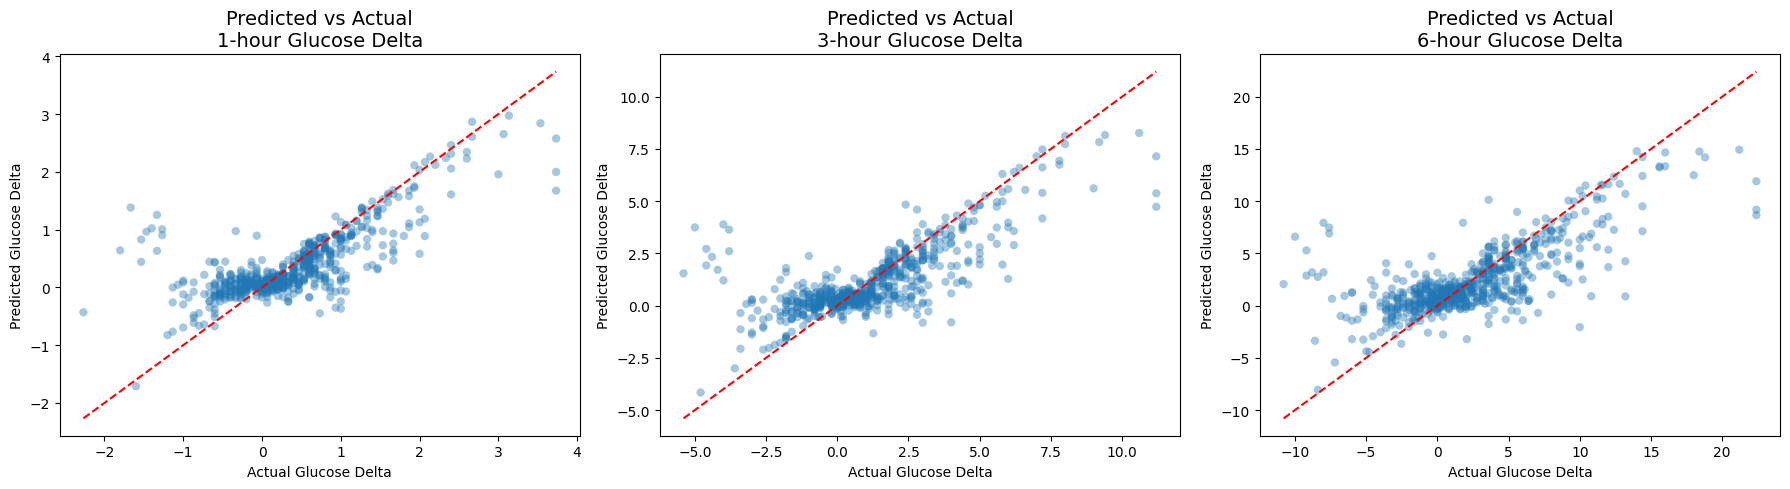

In [24]:
import matplotlib.pyplot as plt
import numpy as np

HORIZONS = ["h1", "h3", "h6"]
titles = {
    "h1": "1-hour Glucose Delta",
    "h3": "3-hour Glucose Delta",
    "h6": "6-hour Glucose Delta"
}

plt.figure(figsize=(18, 5))

for i, horizon in enumerate(HORIZONS):

    y_true = Y_test[:, i]
    y_pred = models[horizon].predict(X_test)

    # Plot
    plt.subplot(1, 3, i+1)
    plt.scatter(y_true, y_pred, alpha=0.4, edgecolors='none')

    # Line y = x (perfect prediction)
    min_val = min(np.min(y_true), np.min(y_pred))
    max_val = max(np.max(y_true), np.max(y_pred))
    plt.plot([min_val, max_val], [min_val, max_val], 'r--')

    plt.title(f"Predicted vs Actual\n{titles[horizon]}", fontsize=14)
    plt.xlabel("Actual Glucose Delta")
    plt.ylabel("Predicted Glucose Delta")

plt.tight_layout()
plt.show()


#RESIDUAL PLOTS (H1, H3, H6)

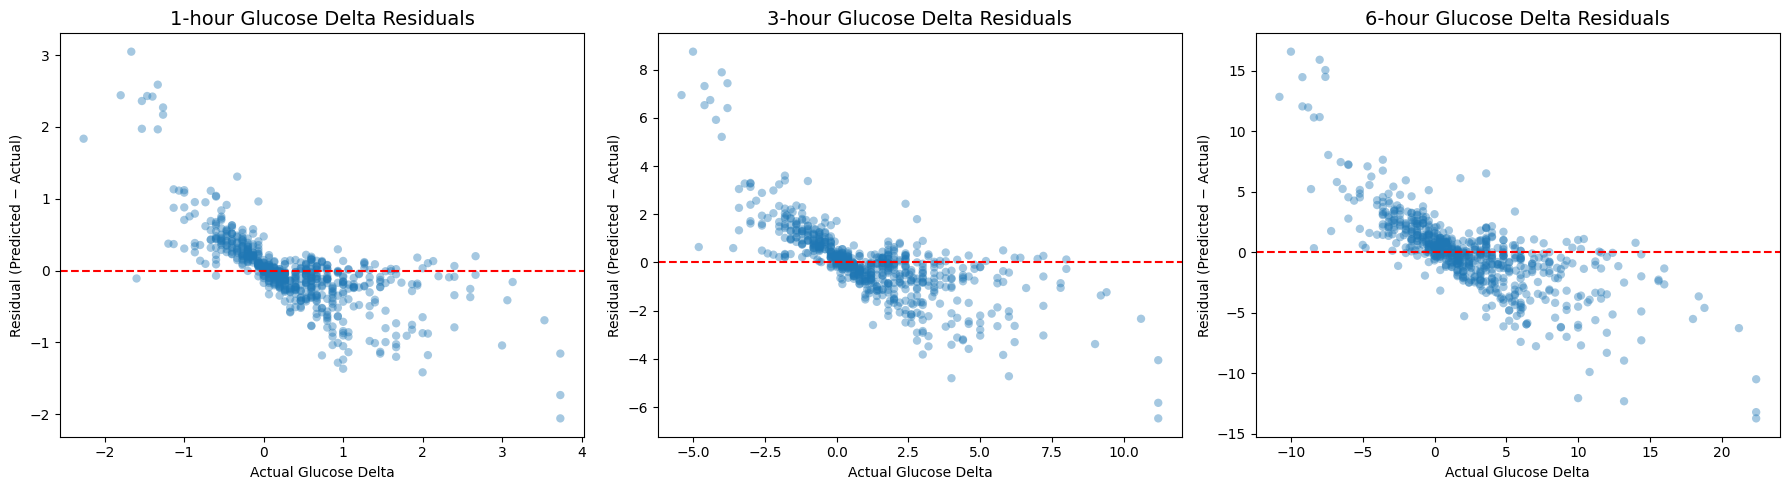

In [25]:
import matplotlib.pyplot as plt
import numpy as np

HORIZONS = ["h1", "h3", "h6"]
titles = {
    "h1": "1-hour Glucose Delta Residuals",
    "h3": "3-hour Glucose Delta Residuals",
    "h6": "6-hour Glucose Delta Residuals"
}

plt.figure(figsize=(18, 5))

for i, horizon in enumerate(HORIZONS):

    y_true = Y_test[:, i]
    y_pred = models[horizon].predict(X_test)

    residuals = y_pred - y_true

    plt.subplot(1, 3, i+1)
    plt.scatter(y_true, residuals, alpha=0.4, edgecolors='none')

    # Zero-error line
    plt.axhline(0, color='red', linestyle='--')

    plt.title(titles[horizon], fontsize=14)
    plt.xlabel("Actual Glucose Delta")
    plt.ylabel("Residual (Predicted − Actual)")

plt.tight_layout()
plt.show()


Building SHAP explainer for h1...
Building SHAP explainer for h3...
Building SHAP explainer for h6...

================ SHAP SUMMARY: h1 ================



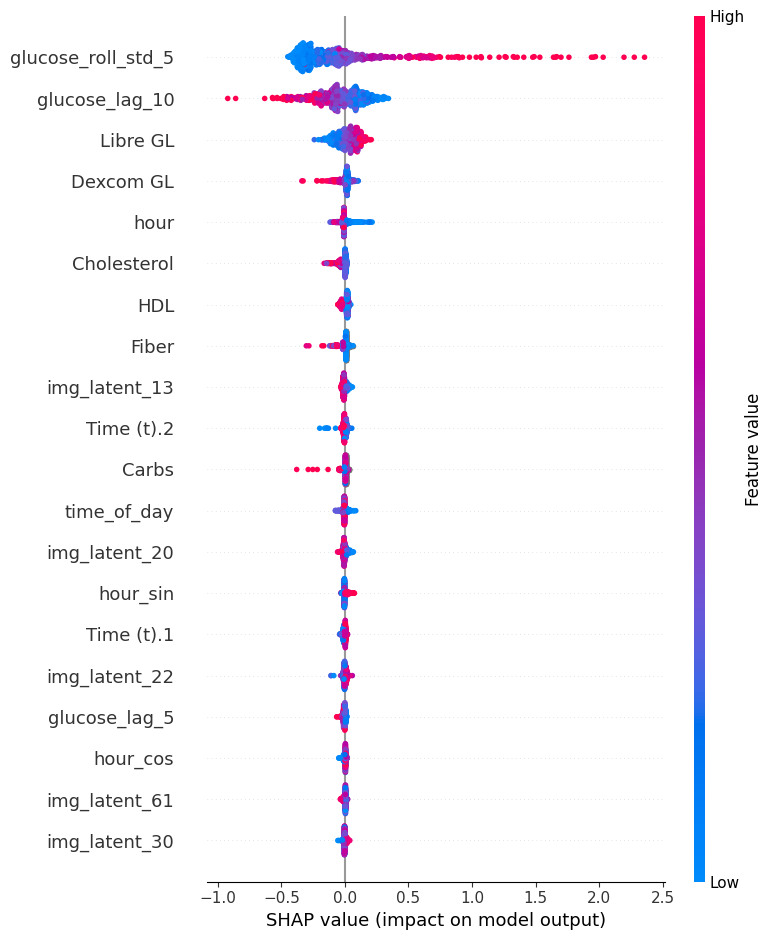


================ SHAP SUMMARY: h3 ================



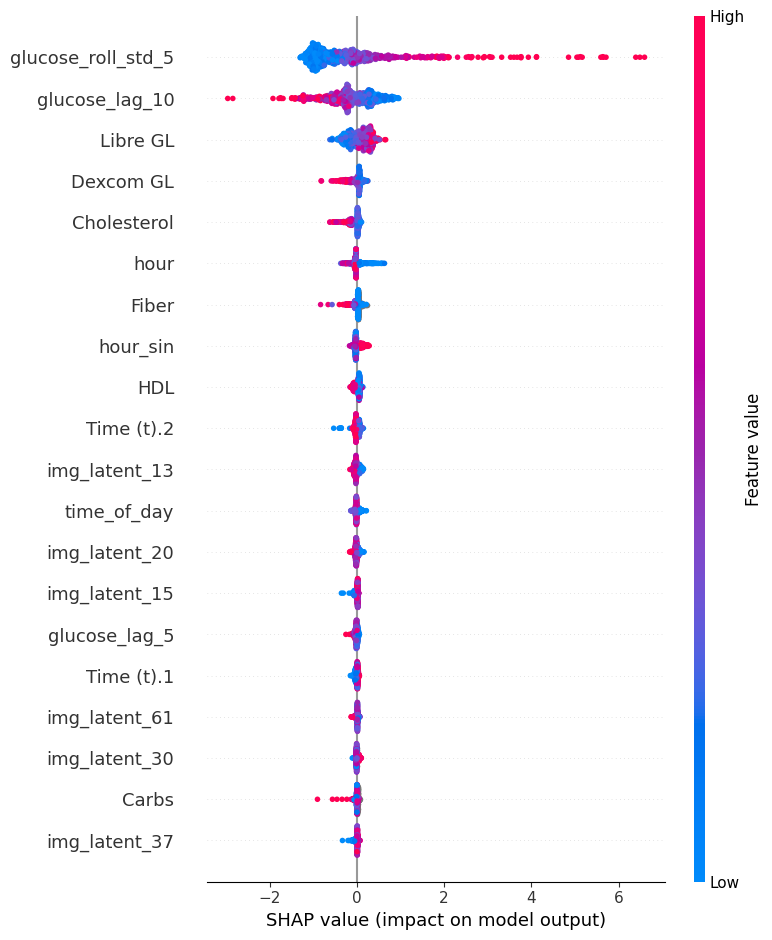


================ SHAP SUMMARY: h6 ================



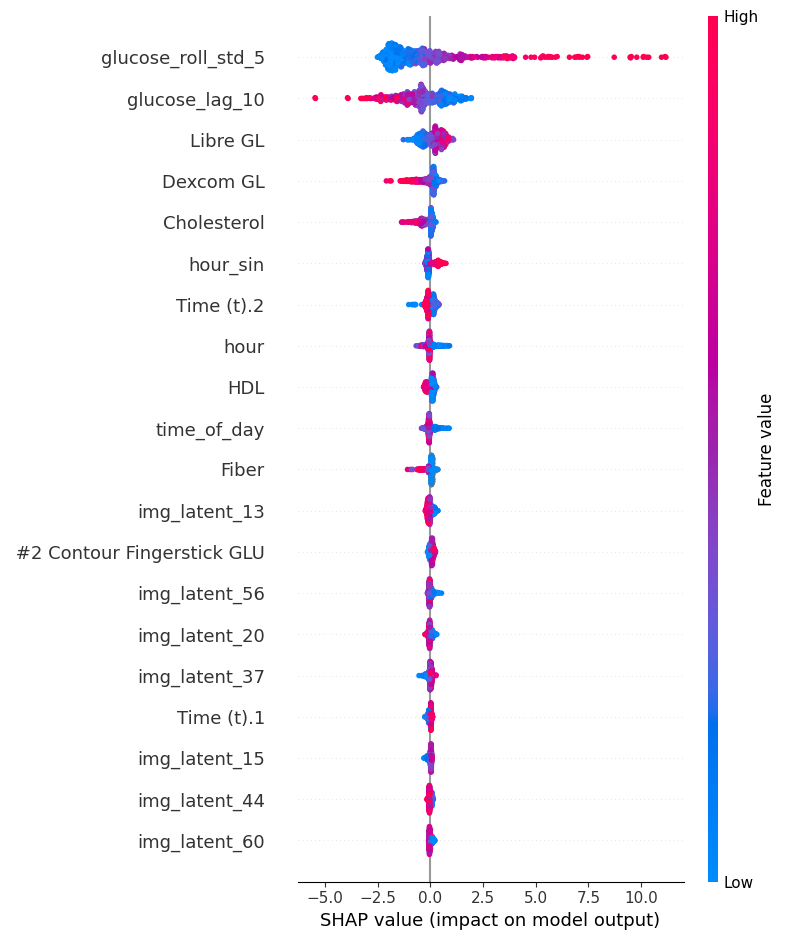

In [26]:
!pip install shap
import shap
import numpy as np
import matplotlib.pyplot as plt

# Use 500 random training samples as background for efficiency
background_size = min(500, X_train.shape[0])
background_idx = np.random.choice(X_train.shape[0], background_size, replace=False)
background = X_train[background_idx]


# Create SHAP explainers for each horizon
explainers = {}
HORIZONS = ["h1", "h3", "h6"]

for i, horizon in enumerate(HORIZONS):
    print(f"Building SHAP explainer for {horizon}...")
    explainers[horizon] = shap.TreeExplainer(models[horizon])


#  GLOBAL SHAP SUMMARY PLOTS

for i, horizon in enumerate(HORIZONS):
    print(f"\n================ SHAP SUMMARY: {horizon} ================\n")

    # Compute SHAP values for the test set
    shap_values = explainers[horizon].shap_values(X_test)

    # Summary Plot (most important features)
    shap.summary_plot(
        shap_values,
        X_test,
        feature_names=feature_cols,
        show=True
    )



================ SHAP BAR PLOT: h1 ================



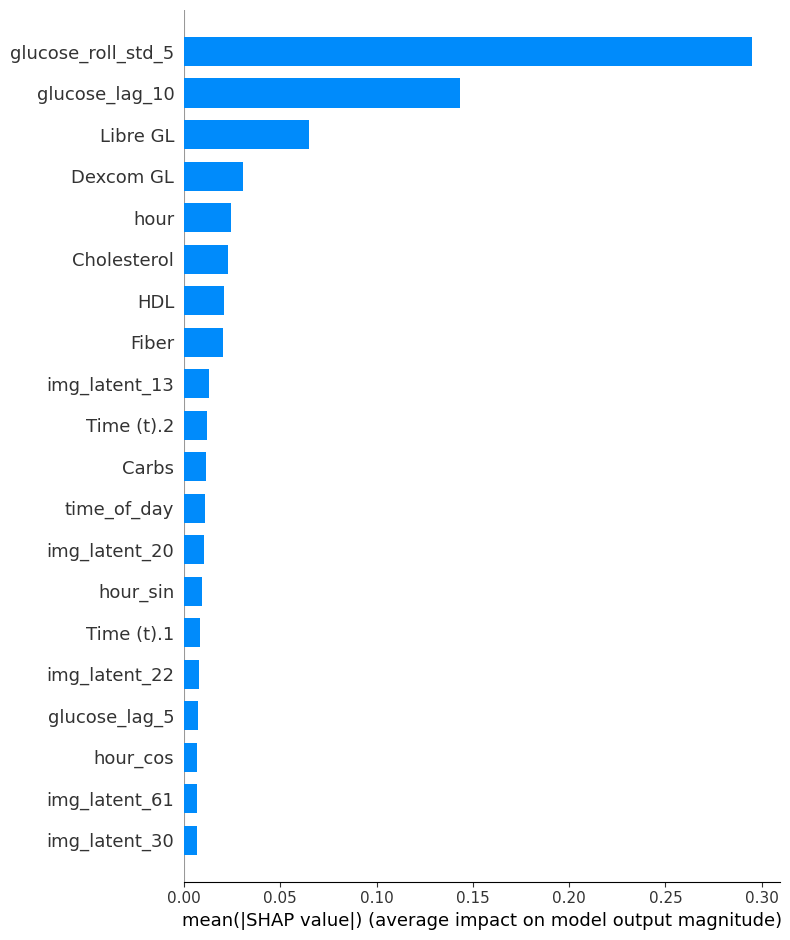


================ SHAP BAR PLOT: h3 ================



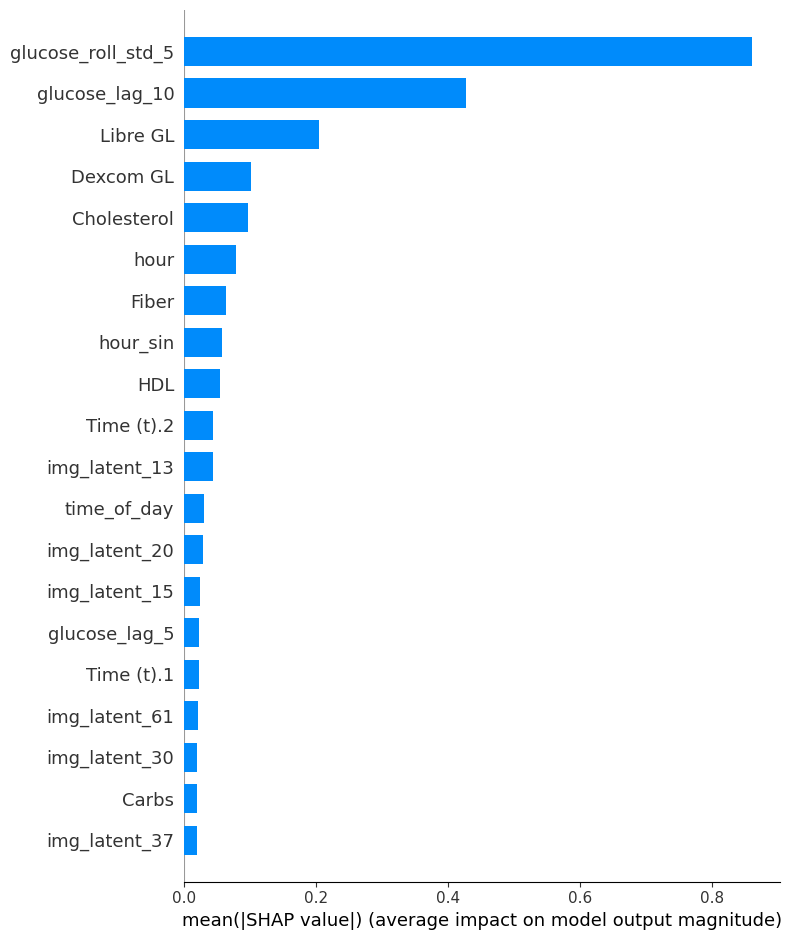


================ SHAP BAR PLOT: h6 ================



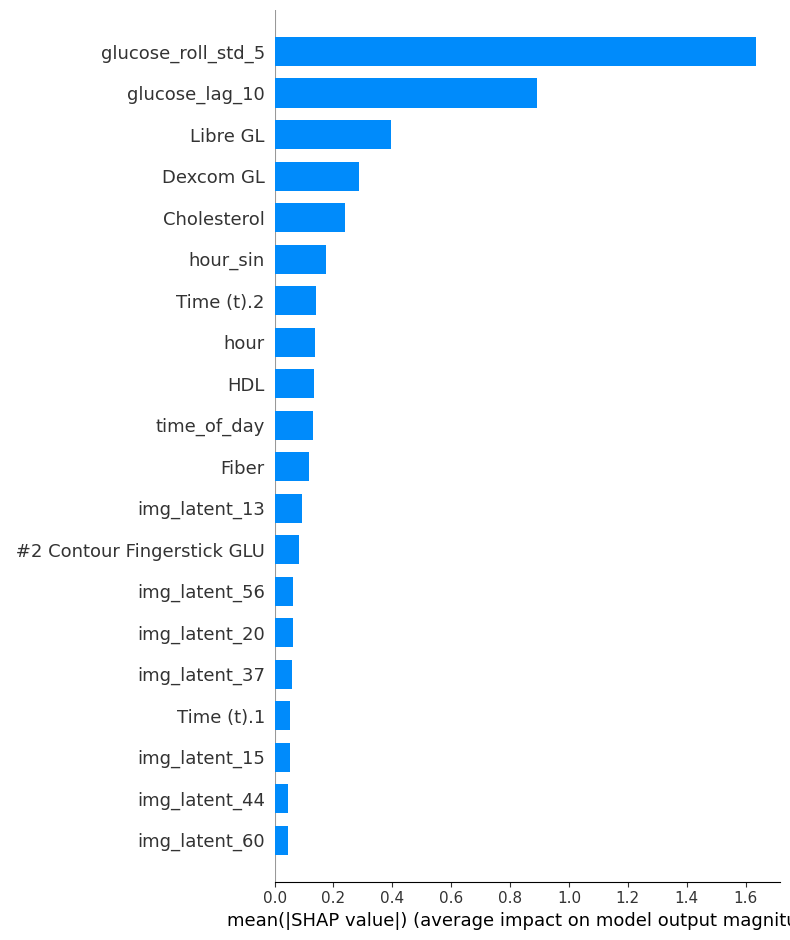

In [27]:
for i, horizon in enumerate(HORIZONS):
    shap_values = explainers[horizon].shap_values(X_test)
    print(f"\n================ SHAP BAR PLOT: {horizon} ================\n")

    shap.summary_plot(
        shap_values,
        X_test,
        feature_names=feature_cols,
        plot_type="bar",
        show=True
    )


#LightGBM

In [28]:
from lightgbm import LGBMRegressor
import lightgbm as lgb # Added this import statement
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import pandas as pd

print("\n================ TRAINING LIGHTGBM MODELS ================\n")

lgbm_models = {}
lgbm_results = []

HORIZONS = ["h1", "h3", "h6"]

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- Training LightGBM model for glucose_delta_{horizon} -----")

    y_train_h = Y_train[:, i]
    y_val_h   = Y_val[:, i]

    model = LGBMRegressor(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=64,
        max_depth=-1,
        subsample=0.8,
        subsample_freq=5,
        colsample_bytree=0.9,
        reg_alpha=0.0,
        reg_lambda=1.0,
        random_state=42,
        verbosity=-1
    )

    model.fit(
        X_train, y_train_h,
        eval_set=[(X_val, y_val_h)],
        eval_metric="rmse",
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)]
    )

    lgbm_models[horizon] = model

    # Test prediction
    y_test_h = Y_test[:, i]
    y_pred_test = model.predict(X_test)

    r2 = r2_score(y_test_h, y_pred_test)
    rmse = mean_squared_error(y_test_h, y_pred_test) ** 0.5

    print(f"LightGBM Model for {horizon}: R2 = {r2:.4f}, RMSE = {rmse:.4f}")

    lgbm_results.append([horizon, r2, rmse])

# Result table
lgbm_results_df = pd.DataFrame(lgbm_results, columns=["Horizon", "R2", "RMSE"])

print("\n================ LIGHTGBM TRAINING COMPLETE ================\n")
display(lgbm_results_df)


================ TRAINING LIGHTGBM MODELS ================


----- Training LightGBM model for glucose_delta_h1 -----
LightGBM Model for h1: R2 = 0.6488, RMSE = 0.4704

----- Training LightGBM model for glucose_delta_h3 -----
LightGBM Model for h3: R2 = 0.6192, RMSE = 1.4653

----- Training LightGBM model for glucose_delta_h6 -----
LightGBM Model for h6: R2 = 0.5813, RMSE = 3.1070

================ LIGHTGBM TRAINING COMPLETE ================



,Horizon,R2,RMSE
0,h1,0.648840,0.470435
1,h3,0.619150,1.465332
2,h6,0.581271,3.106971


# VALIDATION PERFORMANCE (H1, H3, H6)


In [29]:

val_results = []

print("\n================ LIGHTGBM VALIDATION EVALUATION ================\n")

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- Evaluating validation model for glucose_delta_{horizon} -----")

    y_val_true = Y_val[:, i]
    y_val_pred = lgbm_models[horizon].predict(X_val)

    r2 = r2_score(y_val_true, y_val_pred)
    rmse = mean_squared_error(y_val_true, y_val_pred) ** 0.5

    print(f"Val R2 = {r2:.4f},   Val RMSE = {rmse:.4f}")

    val_results.append([horizon, r2, rmse])

val_results_df = pd.DataFrame(val_results, columns=["Horizon", "Val_R2", "Val_RMSE"])

print("\n================ VALIDATION COMPLETE ================\n")
display(val_results_df)



================ LIGHTGBM VALIDATION EVALUATION ================


----- Evaluating validation model for glucose_delta_h1 -----
Val R2 = 0.6119,   Val RMSE = 0.3951

----- Evaluating validation model for glucose_delta_h3 -----
Val R2 = 0.5971,   Val RMSE = 1.1944

----- Evaluating validation model for glucose_delta_h6 -----
Val R2 = 0.5553,   Val RMSE = 2.5378

================ VALIDATION COMPLETE ================



,Horizon,Val_R2,Val_RMSE
0,h1,0.611929,0.395115
1,h3,0.597106,1.194434
2,h6,0.555350,2.537844


# TEST PERFORMANCE (H1, H3, H6)

In [30]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

test_results = []

print("\n================ LIGHTGBM TEST EVALUATION ================\n")

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- Evaluating TEST model for glucose_delta_{horizon} -----")

    y_test_true = Y_test[:, i]
    y_test_pred = lgbm_models[horizon].predict(X_test)

    # Metrics
    r2 = r2_score(y_test_true, y_test_pred)

    # Manual RMSE (old sklearn versions do not support squared=False)
    rmse = np.sqrt(mean_squared_error(y_test_true, y_test_pred))

    mae = mean_absolute_error(y_test_true, y_test_pred)

    # Safe MAPE (ignore zero targets)
    safe_true = np.where(y_test_true == 0, np.nan, y_test_true)
    mape = np.nanmean(np.abs((y_test_true - y_test_pred) / safe_true)) * 100

    print(
        f"TEST R2 = {r2:.4f},   "
        f"TEST RMSE = {rmse:.4f},   "
        f"TEST MAE = {mae:.4f},   "
        f"TEST MAPE = {mape:.2f}%"
    )

    test_results.append([horizon, r2, rmse, mae, mape])

test_results_df = pd.DataFrame(
    test_results,
    columns=["Horizon", "Test_R2", "Test_RMSE", "Test_MAE", "Test_MAPE"]
)

print("\n================ TEST EVALUATION COMPLETE ================\n")
display(test_results_df)



================ LIGHTGBM TEST EVALUATION ================


----- Evaluating TEST model for glucose_delta_h1 -----
TEST R2 = 0.6488,   TEST RMSE = 0.4704,   TEST MAE = 0.3034,   TEST MAPE = 70.08%

----- Evaluating TEST model for glucose_delta_h3 -----
TEST R2 = 0.6192,   TEST RMSE = 1.4653,   TEST MAE = 0.9816,   TEST MAPE = 79.63%

----- Evaluating TEST model for glucose_delta_h6 -----
TEST R2 = 0.5813,   TEST RMSE = 3.1070,   TEST MAE = 2.0839,   TEST MAPE = 90.74%

================ TEST EVALUATION COMPLETE ================



,Horizon,Test_R2,Test_RMSE,Test_MAE,Test_MAPE
0,h1,0.648840,0.470435,0.303431,70.078075
1,h3,0.619150,1.465332,0.981629,79.633593
2,h6,0.581271,3.106971,2.083939,90.744661


#PREDICTED vs ACTUAL SCATTER PLOTS (H1, H3, H6)

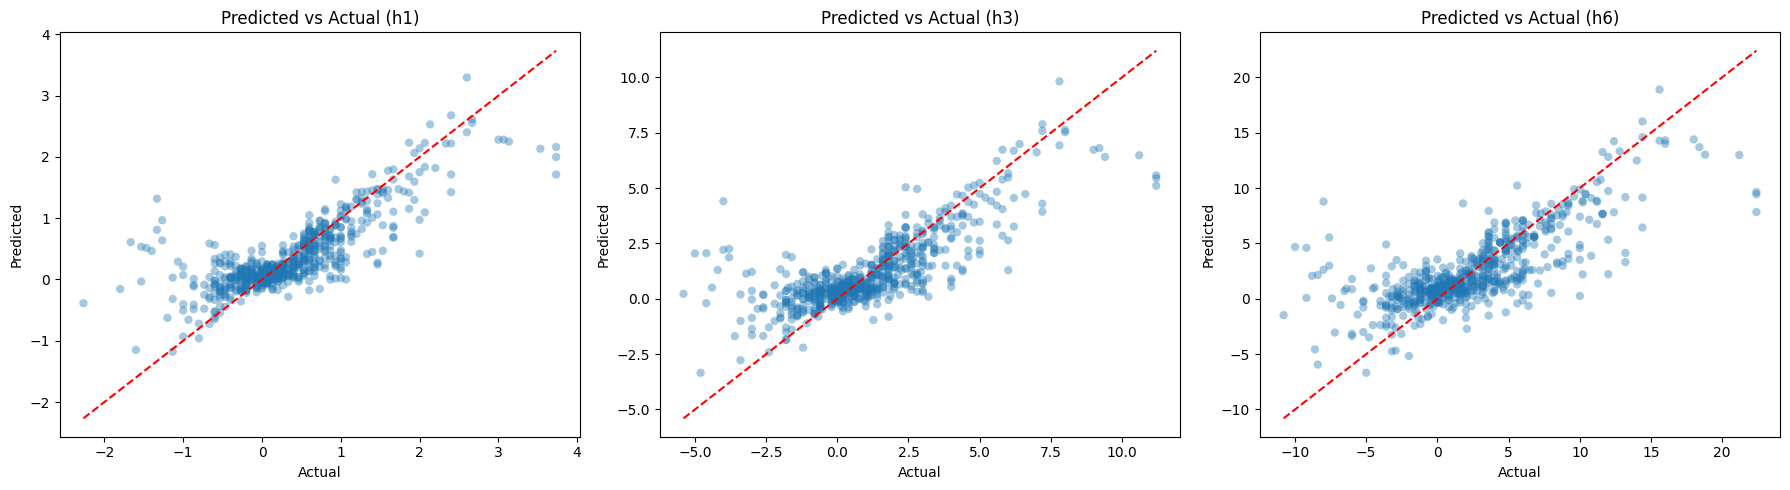

In [31]:
plt.figure(figsize=(18, 5))

for i, horizon in enumerate(HORIZONS):

    y_true = Y_test[:, i]
    y_pred = lgbm_models[horizon].predict(X_test)

    plt.subplot(1, 3, i+1)
    plt.scatter(y_true, y_pred, alpha=0.4, edgecolors='none')

    min_val = min(np.min(y_true), np.min(y_pred))
    max_val = max(np.max(y_true), np.max(y_pred))
    plt.plot([min_val, max_val], [min_val, max_val], 'r--')

    plt.title(f"Predicted vs Actual ({horizon})")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")

plt.tight_layout()
plt.show()


#RESIDUAL PLOTS (H1, H3, H6)

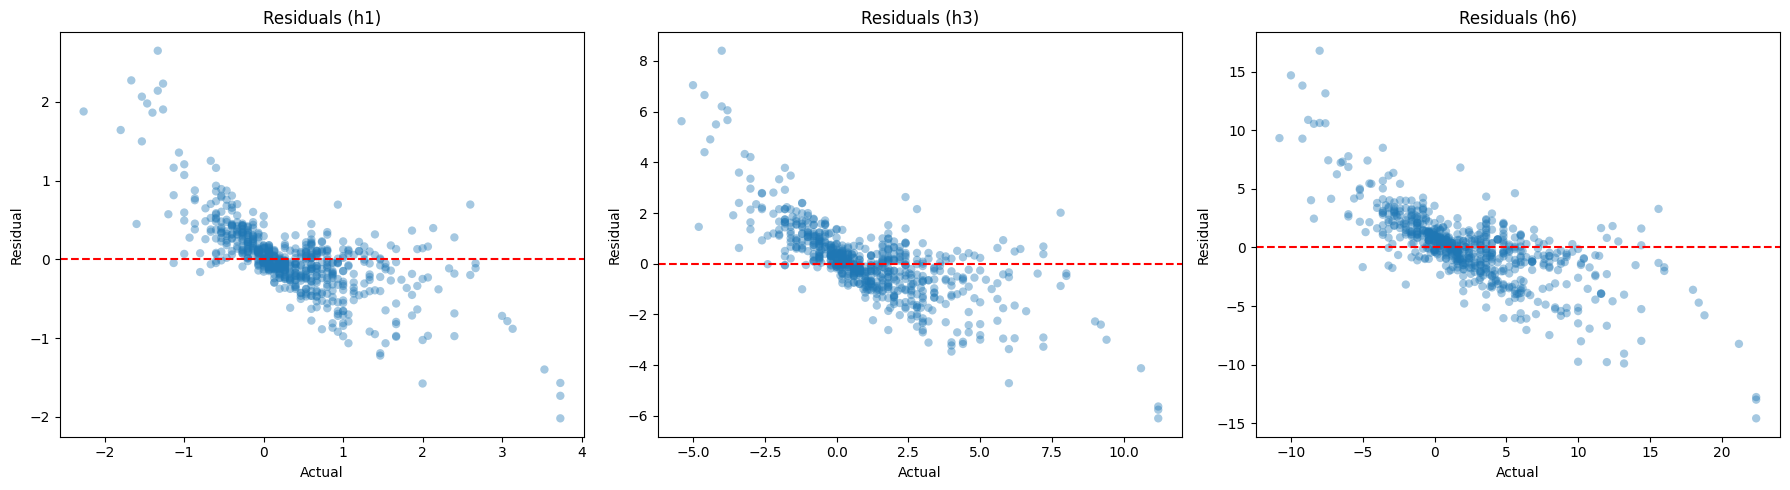

In [32]:
plt.figure(figsize=(18, 5))

for i, horizon in enumerate(HORIZONS):

    y_true = Y_test[:, i]
    y_pred = lgbm_models[horizon].predict(X_test)

    residuals = y_pred - y_true

    plt.subplot(1, 3, i+1)
    plt.scatter(y_true, residuals, alpha=0.4, edgecolors='none')
    plt.axhline(0, color='red', linestyle='--')

    plt.title(f"Residuals ({horizon})")
    plt.xlabel("Actual")
    plt.ylabel("Residual")

plt.tight_layout()
plt.show()


#SHAP EXPLANATION FOR LIGHTGBM (H1, H3, H6)


================ SHAP ANALYSIS FOR LIGHTGBM MODELS ================




----- SHAP Analysis for glucose_delta_h1 -----



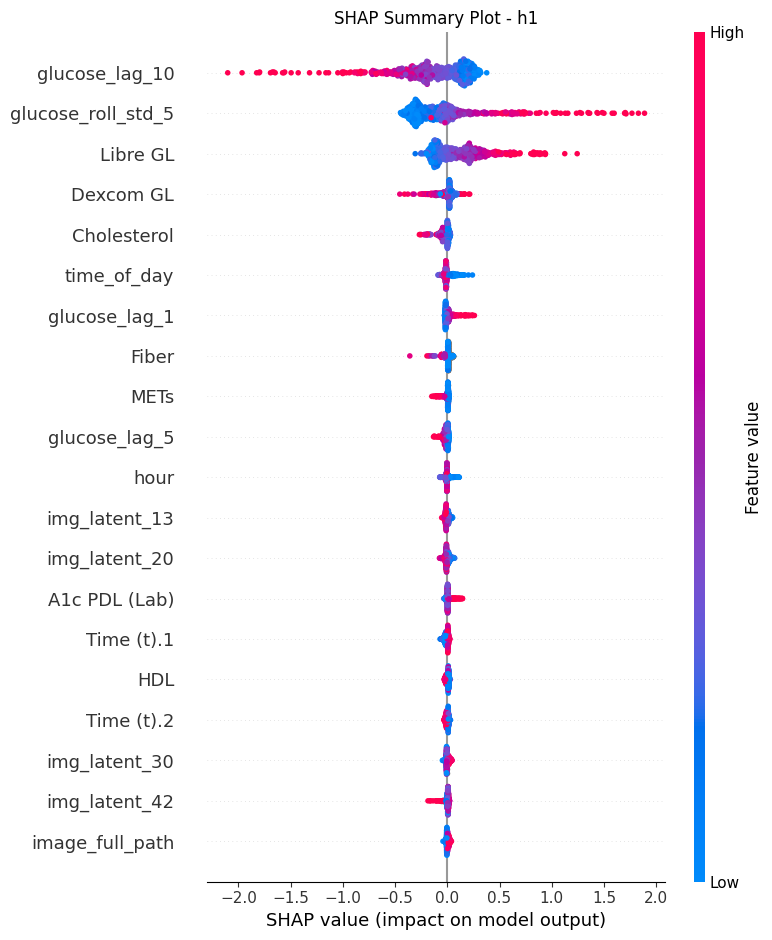

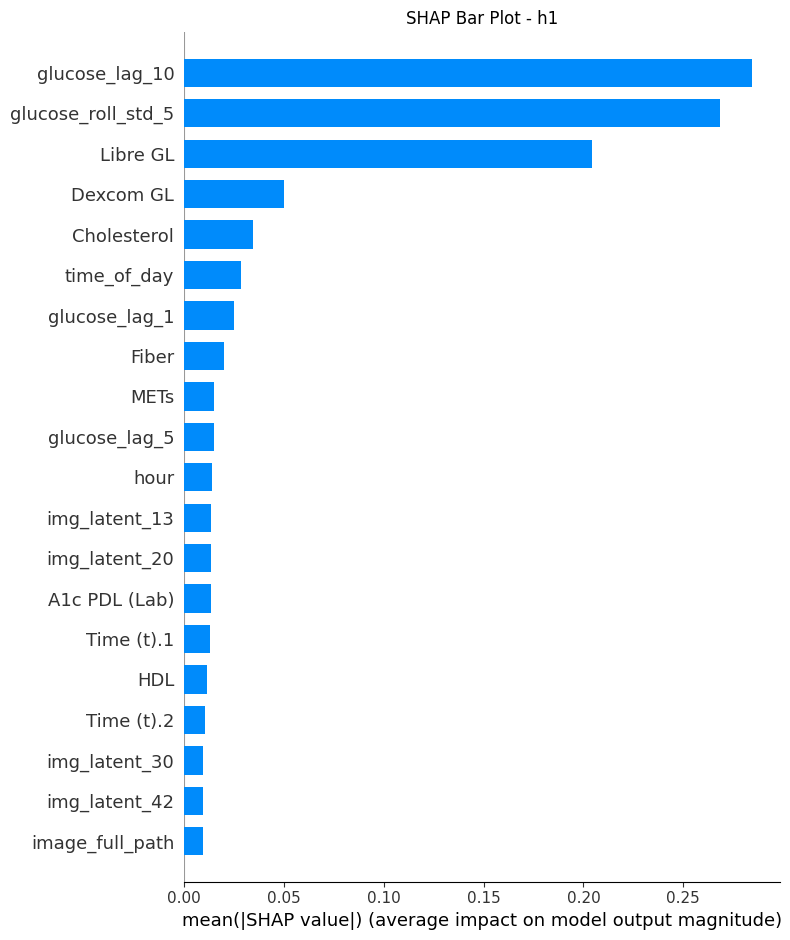

Top feature for h1: glucose_lag_10


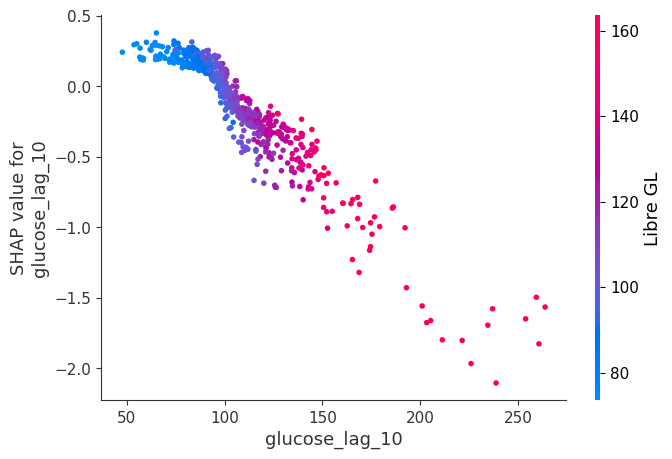


----- SHAP Analysis for glucose_delta_h3 -----



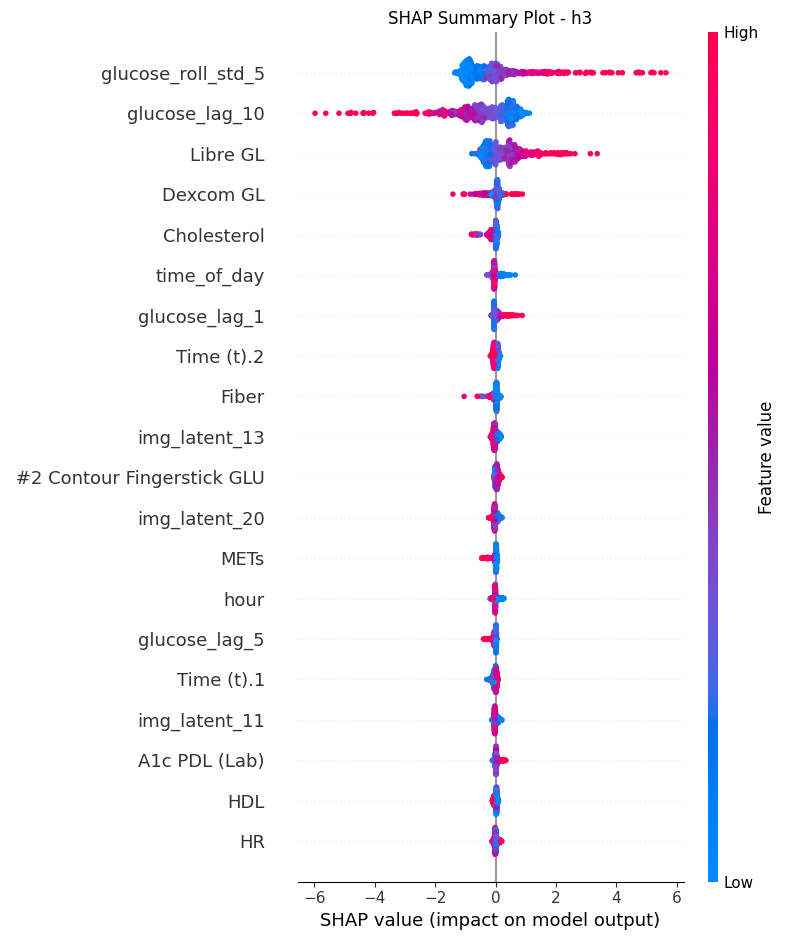

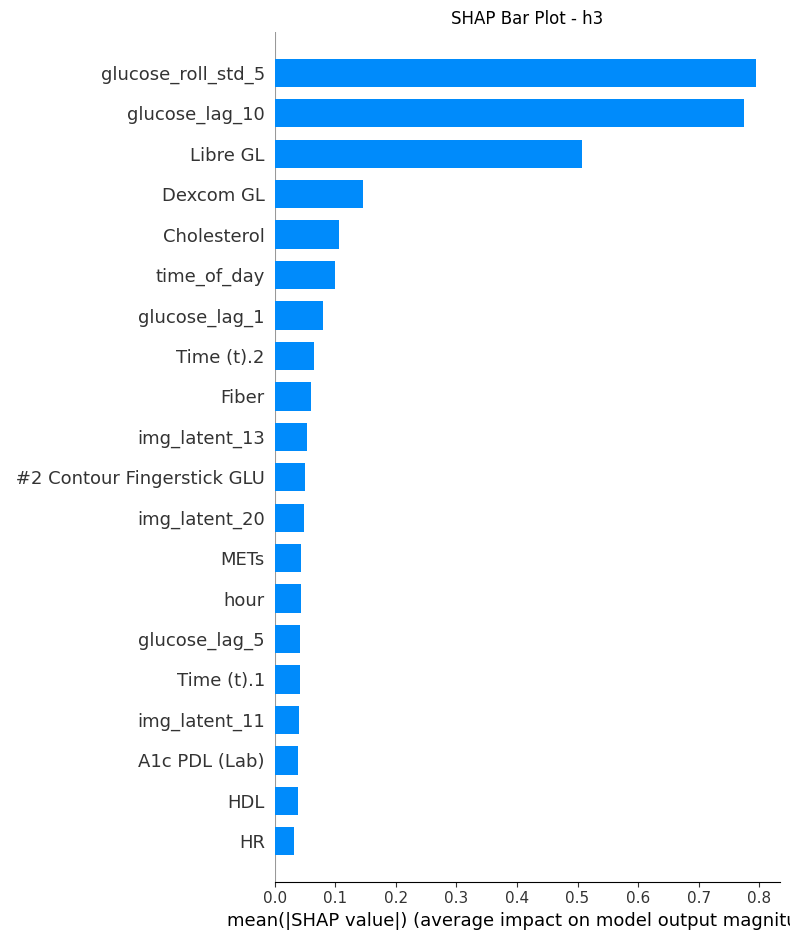

Top feature for h3: glucose_roll_std_5


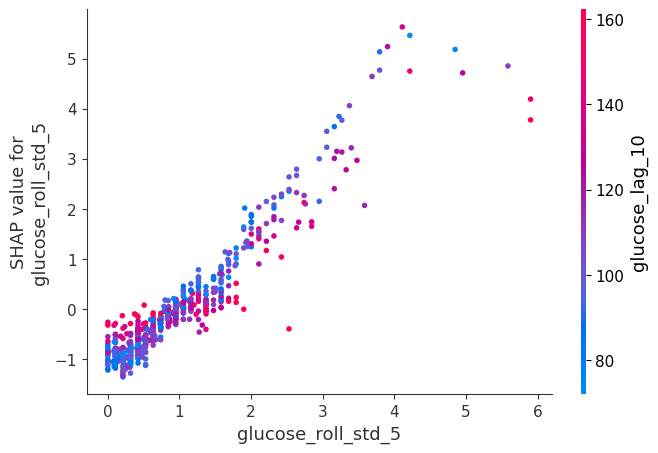


----- SHAP Analysis for glucose_delta_h6 -----



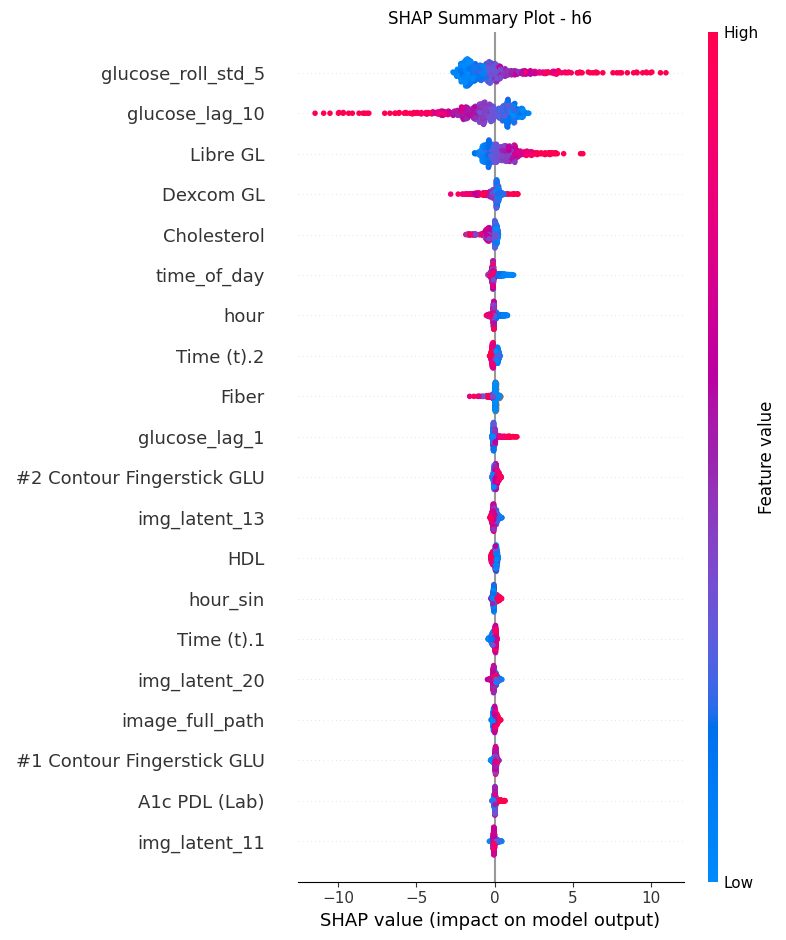

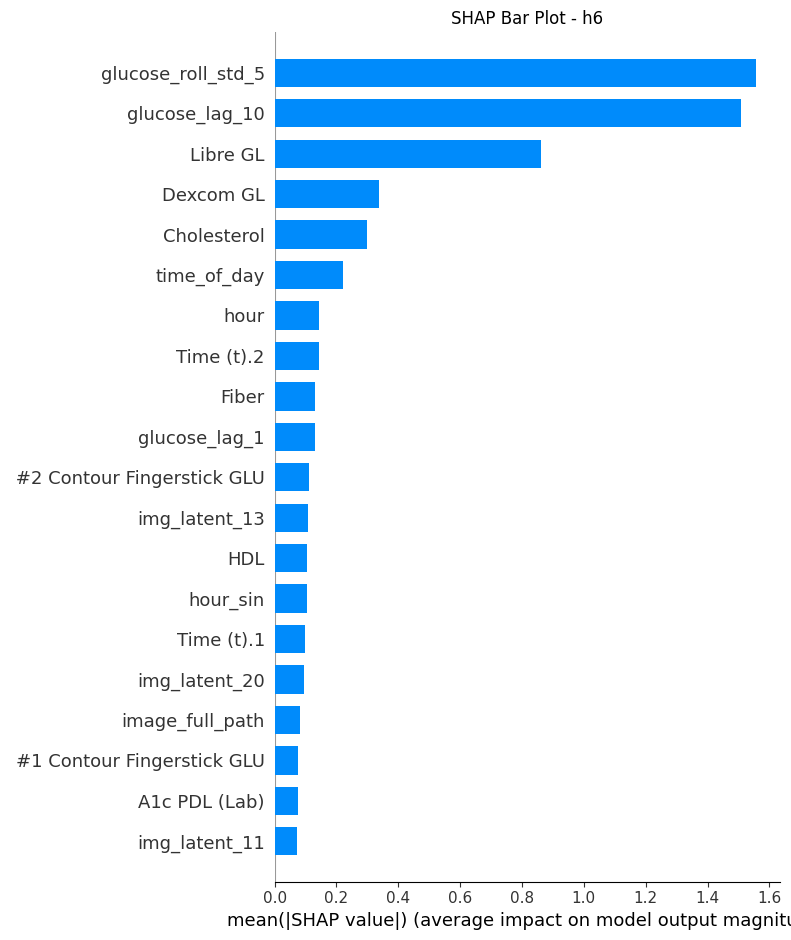

Top feature for h6: glucose_roll_std_5


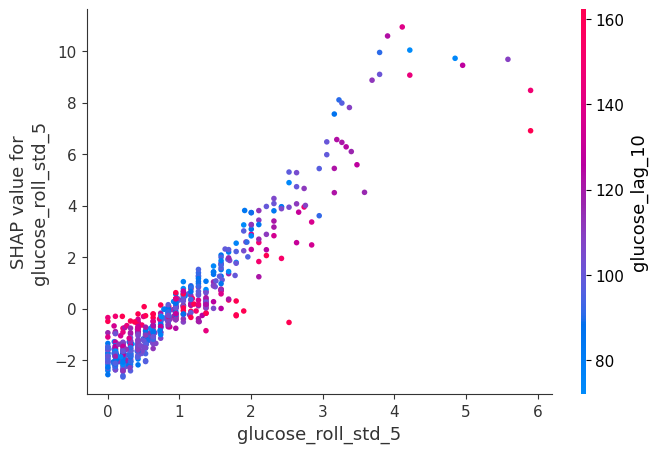


================ SHAP ANALYSIS COMPLETE ================



In [33]:
import shap
import matplotlib.pyplot as plt
import numpy as np

print("\n================ SHAP ANALYSIS FOR LIGHTGBM MODELS ================\n")

# Convert X_test into a DataFrame (needed for SHAP feature names)
X_test_df = pd.DataFrame(X_test, columns=feature_cols)

# Initialise JS for notebook
shap.initjs()

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- SHAP Analysis for glucose_delta_{horizon} -----\n")

    model = lgbm_models[horizon]

    # Create SHAP explainer
    explainer = shap.TreeExplainer(model)

    # Get SHAP values (LightGBM returns list for multiclass/multioutput)
    shap_values = explainer.shap_values(X_test_df)

    # If shap_values is a list, select correct output dimension
    if isinstance(shap_values, list):
        shap_values = shap_values[i]   # select h1 / h3 / h6 output

    # =============================== SUMMARY PLOT ===============================
    plt.title(f"SHAP Summary Plot - {horizon}")
    shap.summary_plot(shap_values, X_test_df, show=True)

    # =============================== BAR PLOT ===================================
    plt.title(f"SHAP Bar Plot - {horizon}")
    shap.summary_plot(shap_values, X_test_df, plot_type="bar", show=True)

    # =========================== DEPENDENCE PLOT ===============================
    # Find top feature by mean absolute SHAP value
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    top_feature = feature_cols[np.argmax(mean_abs_shap)]

    print(f"Top feature for {horizon}: {top_feature}")

    shap.dependence_plot(top_feature, shap_values, X_test_df, show=True)

print("\n================ SHAP ANALYSIS COMPLETE ================\n")


#CATBOOST

In [34]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.3 MB/s eta 0:00:00


#CATBOOST

In [35]:
# 1. TRAIN

from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import pandas as pd

print("\n================ TRAINING CATBOOST MODELS ================\n")

cat_models = {}
cat_results = []

HORIZONS = ["h1", "h3", "h6"]

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- Training CatBoost model for glucose_delta_{horizon} -----")

    y_train_h = Y_train[:, i]
    y_val_h   = Y_val[:, i]

    model = CatBoostRegressor(
        loss_function="RMSE",
        learning_rate=0.03,
        depth=7,
        iterations=2000,
        l2_leaf_reg=3.0,
        random_seed=42,

        # ---- FIXED HERE ----
        bootstrap_type="Bernoulli",
        subsample=0.8,
        rsm=0.9,
        # ----------------------

        verbose=0
    )

    model.fit(
        X_train, y_train_h,
        eval_set=(X_val, y_val_h),
        use_best_model=True
    )

    cat_models[horizon] = model

    # Test prediction
    y_test_h = Y_test[:, i]
    y_pred_test = model.predict(X_test)

    r2 = r2_score(y_test_h, y_pred_test)
    rmse = mean_squared_error(y_test_h, y_pred_test) ** 0.5

    print(f"CatBoost Model for {horizon}:  R2 = {r2:.4f},  RMSE = {rmse:.4f}")

    cat_results.append([horizon, r2, rmse])

cat_results_df = pd.DataFrame(cat_results, columns=["Horizon", "R2", "RMSE"])

print("\n================ CATBOOST TRAINING COMPLETE ================\n")
display(cat_results_df)



================ TRAINING CATBOOST MODELS ================


----- Training CatBoost model for glucose_delta_h1 -----
CatBoost Model for h1:  R2 = 0.6013,  RMSE = 0.5013

----- Training CatBoost model for glucose_delta_h3 -----
CatBoost Model for h3:  R2 = 0.5909,  RMSE = 1.5186

----- Training CatBoost model for glucose_delta_h6 -----
CatBoost Model for h6:  R2 = 0.5504,  RMSE = 3.2195

================ CATBOOST TRAINING COMPLETE ================



,Horizon,R2,RMSE
0,h1,0.601255,0.501297
1,h3,0.590943,1.518627
2,h6,0.550402,3.219460


#CATBOOST VALIDATION PERFORMANCE

In [36]:
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import numpy as np

print("\n================ CATBOOST VALIDATION EVALUATION ================\n")

val_results = []

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- Validation for glucose_delta_{horizon} -----")

    y_val_true = Y_val[:, i]
    y_val_pred = cat_models[horizon].predict(X_val)

    r2 = r2_score(y_val_true, y_val_pred)
    # FIX: manual RMSE, no squared=False
    rmse = mean_squared_error(y_val_true, y_val_pred) ** 0.5

    print(f"Val R2   = {r2:.4f}")
    print(f"Val RMSE = {rmse:.4f}")

    val_results.append([horizon, r2, rmse])

cat_val_df = pd.DataFrame(val_results, columns=["Horizon", "Val_R2", "Val_RMSE"])

print("\n================ VALIDATION COMPLETE ================\n")
display(cat_val_df)



================ CATBOOST VALIDATION EVALUATION ================


----- Validation for glucose_delta_h1 -----
Val R2   = 0.5693
Val RMSE = 0.4162

----- Validation for glucose_delta_h3 -----
Val R2   = 0.5615
Val RMSE = 1.2460

----- Validation for glucose_delta_h6 -----
Val R2   = 0.5205
Val RMSE = 2.6354

================ VALIDATION COMPLETE ================



,Horizon,Val_R2,Val_RMSE
0,h1,0.569303,0.416249
1,h3,0.561534,1.246047
2,h6,0.520492,2.635442


#CATBOOST TEST PERFORMANCE

In [37]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

print("\n================ CATBOOST TEST EVALUATION ================\n")

test_results = []

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- TEST for glucose_delta_{horizon} -----")

    y_test_true = Y_test[:, i]
    y_test_pred = cat_models[horizon].predict(X_test)

    # Metrics
    r2 = r2_score(y_test_true, y_test_pred)

    # Manual RMSE (because your sklearn version doesn't support squared=False)
    rmse = mean_squared_error(y_test_true, y_test_pred) ** 0.5

    mae = mean_absolute_error(y_test_true, y_test_pred)

    # ===== FIXED MAPE (ignores zeros) =====
    non_zero_mask = y_test_true != 0
    if np.any(non_zero_mask):
        mape = np.mean(
            np.abs((y_test_true[non_zero_mask] - y_test_pred[non_zero_mask]) /
                   y_test_true[non_zero_mask])
        ) * 100
    else:
        mape = np.nan  # fallback

    print(f"TEST R2   = {r2:.4f}")
    print(f"TEST RMSE = {rmse:.4f}")
    print(f"TEST MAE  = {mae:.4f}")
    print(f"TEST MAPE = {mape:.2f}%")

    test_results.append([horizon, r2, rmse, mae, mape])

cat_test_df = pd.DataFrame(
    test_results,
    columns=["Horizon", "Test_R2", "Test_RMSE", "Test_MAE", "Test_MAPE"]
)

print("\n================ TEST EVALUATION COMPLETE ================\n")
display(cat_test_df)



================ CATBOOST TEST EVALUATION ================


----- TEST for glucose_delta_h1 -----
TEST R2   = 0.6013
TEST RMSE = 0.5013
TEST MAE  = 0.3182
TEST MAPE = 70.85%

----- TEST for glucose_delta_h3 -----
TEST R2   = 0.5909
TEST RMSE = 1.5186
TEST MAE  = 0.9917
TEST MAPE = 76.05%

----- TEST for glucose_delta_h6 -----
TEST R2   = 0.5504
TEST RMSE = 3.2195
TEST MAE  = 2.1307
TEST MAPE = 85.52%

================ TEST EVALUATION COMPLETE ================



,Horizon,Test_R2,Test_RMSE,Test_MAE,Test_MAPE
0,h1,0.601255,0.501297,0.318248,70.853596
1,h3,0.590943,1.518627,0.991690,76.049017
2,h6,0.550402,3.219460,2.130685,85.524040


#PREDICTED vs ACTUAL SCATTER PLOTS (H1, H3, H6)

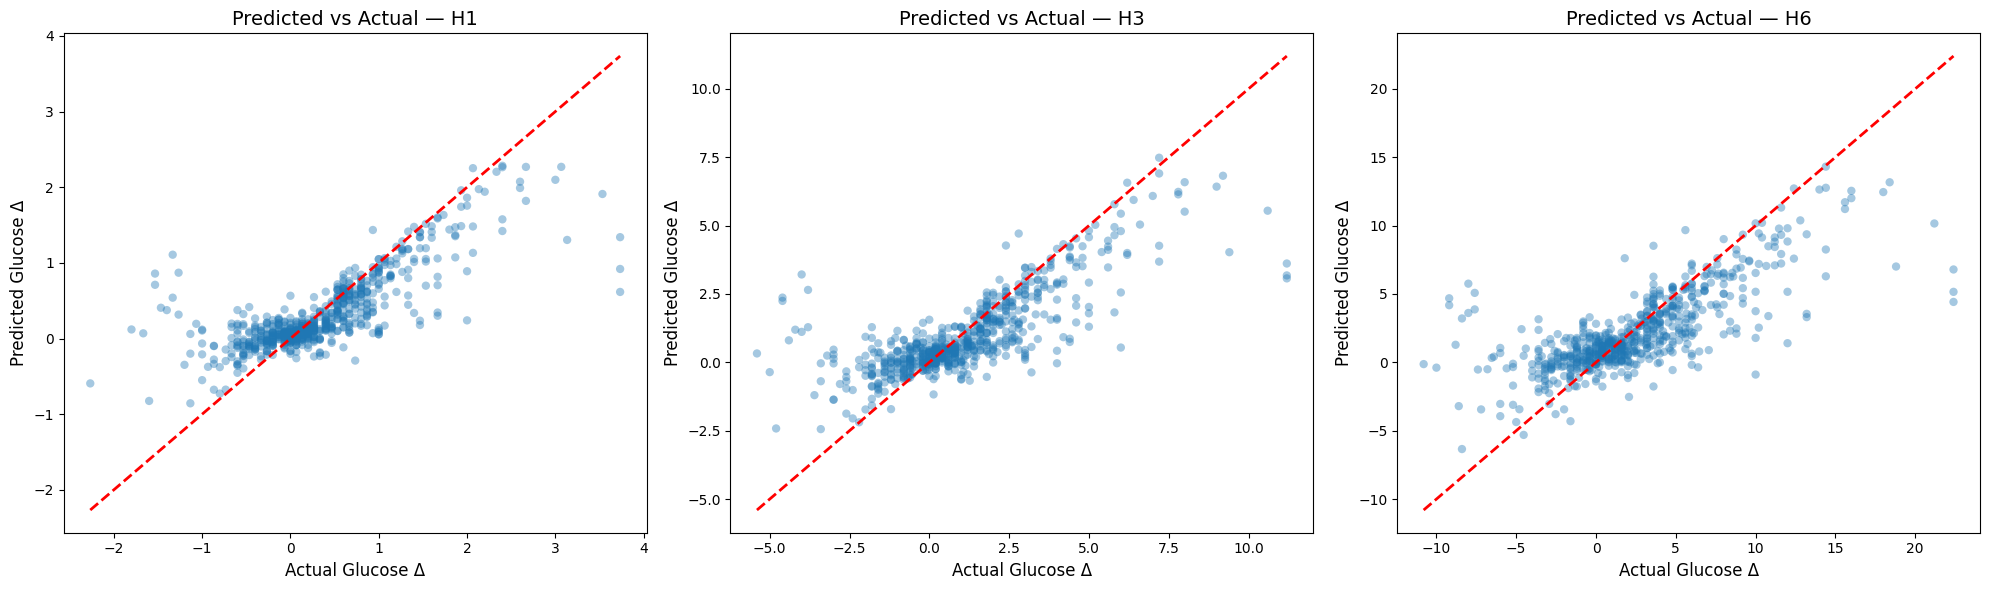

In [38]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(20, 6))

for i, horizon in enumerate(HORIZONS):
    y_true = Y_test[:, i]
    y_pred = cat_models[horizon].predict(X_test)

    plt.subplot(1, 3, i+1)
    plt.scatter(y_true, y_pred, alpha=0.4, edgecolors="none")

    # identity line
    min_v = min(y_true.min(), y_pred.min())
    max_v = max(y_true.max(), y_pred.max())
    plt.plot([min_v, max_v], [min_v, max_v], "r--", linewidth=2)

    plt.title(f"Predicted vs Actual — {horizon.upper()}", fontsize=14)
    plt.xlabel("Actual Glucose Δ", fontsize=12)
    plt.ylabel("Predicted Glucose Δ", fontsize=12)

plt.tight_layout()
plt.show()


#RESIDUAL PLOTS (H1, H3, H6)

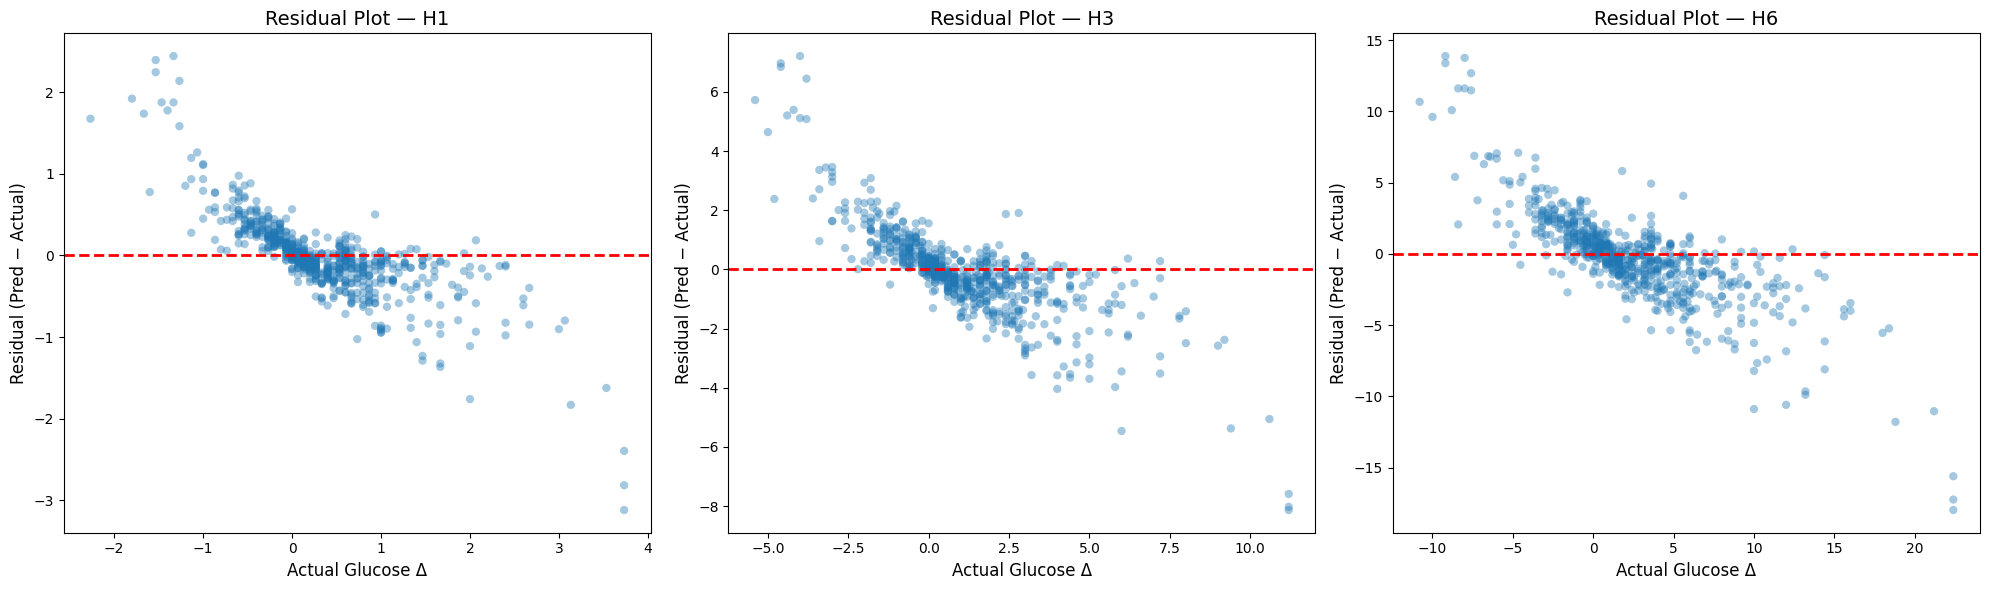

In [39]:
plt.figure(figsize=(20, 6))

for i, horizon in enumerate(HORIZONS):
    y_true = Y_test[:, i]
    y_pred = cat_models[horizon].predict(X_test)
    residuals = y_pred - y_true

    plt.subplot(1, 3, i+1)
    plt.scatter(y_true, residuals, alpha=0.4, edgecolors="none")
    plt.axhline(0, color="red", linestyle="--", linewidth=2)

    plt.title(f"Residual Plot — {horizon.upper()}", fontsize=14)
    plt.xlabel("Actual Glucose Δ", fontsize=12)
    plt.ylabel("Residual (Pred − Actual)", fontsize=12)

plt.tight_layout()
plt.show()


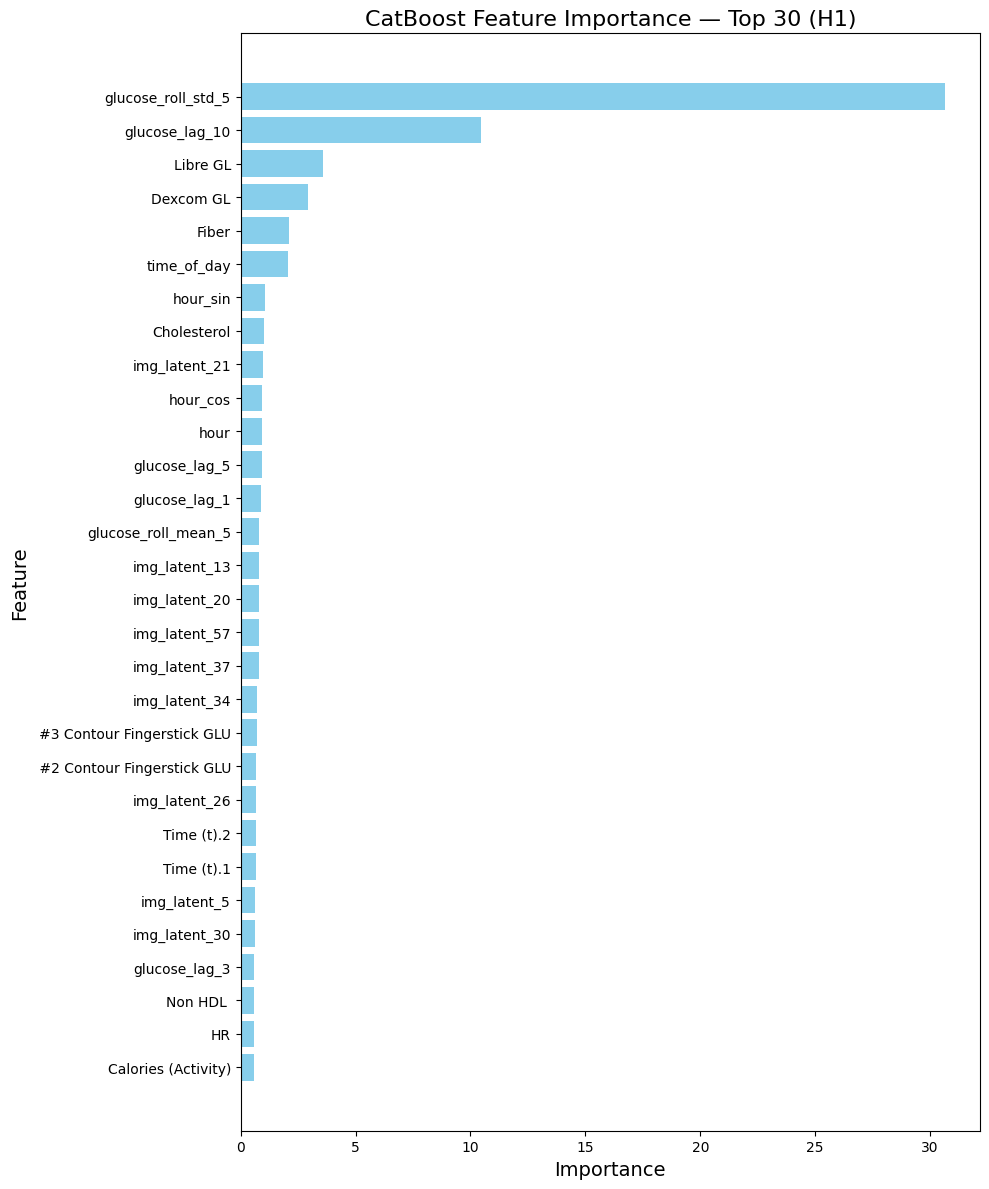

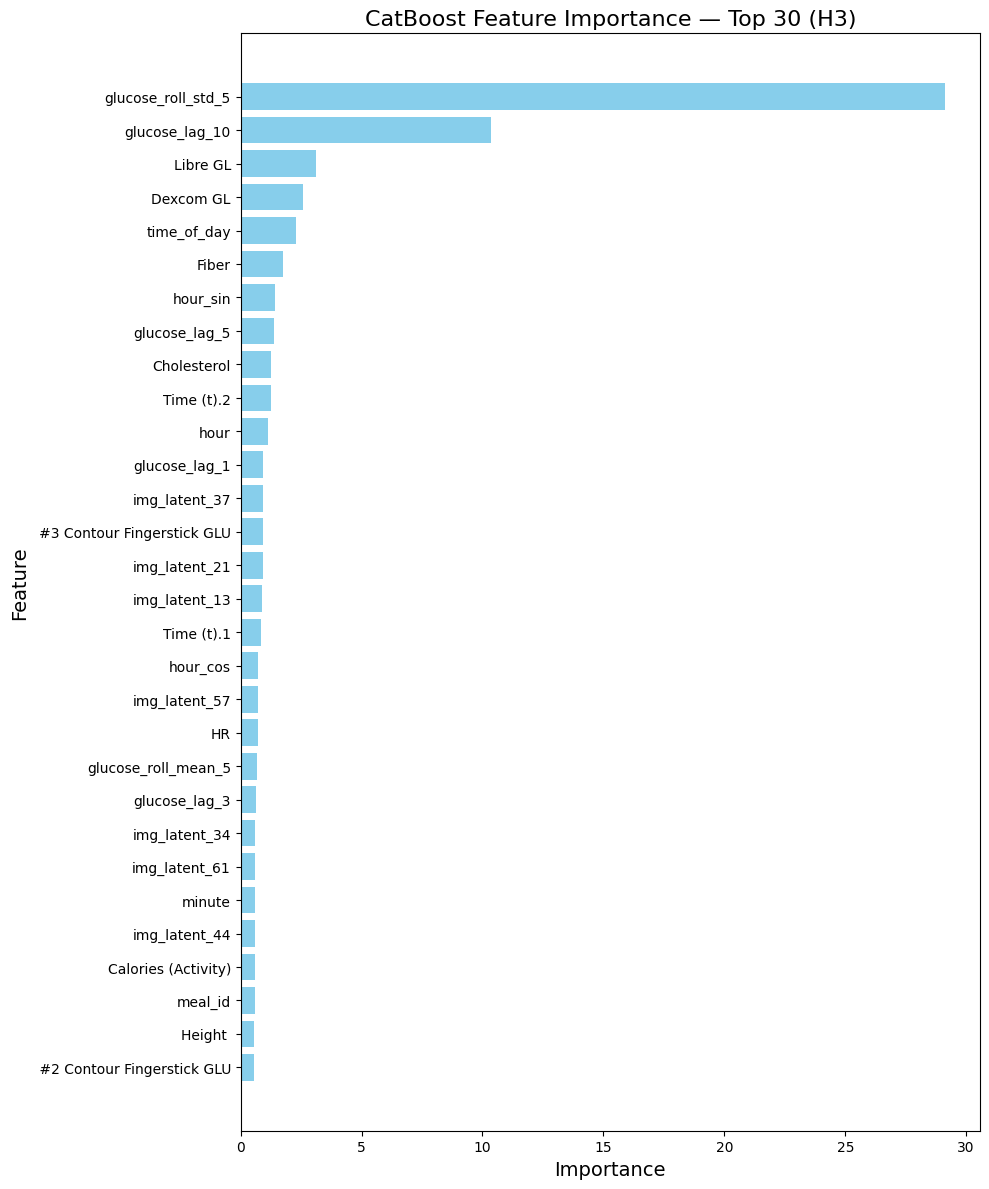

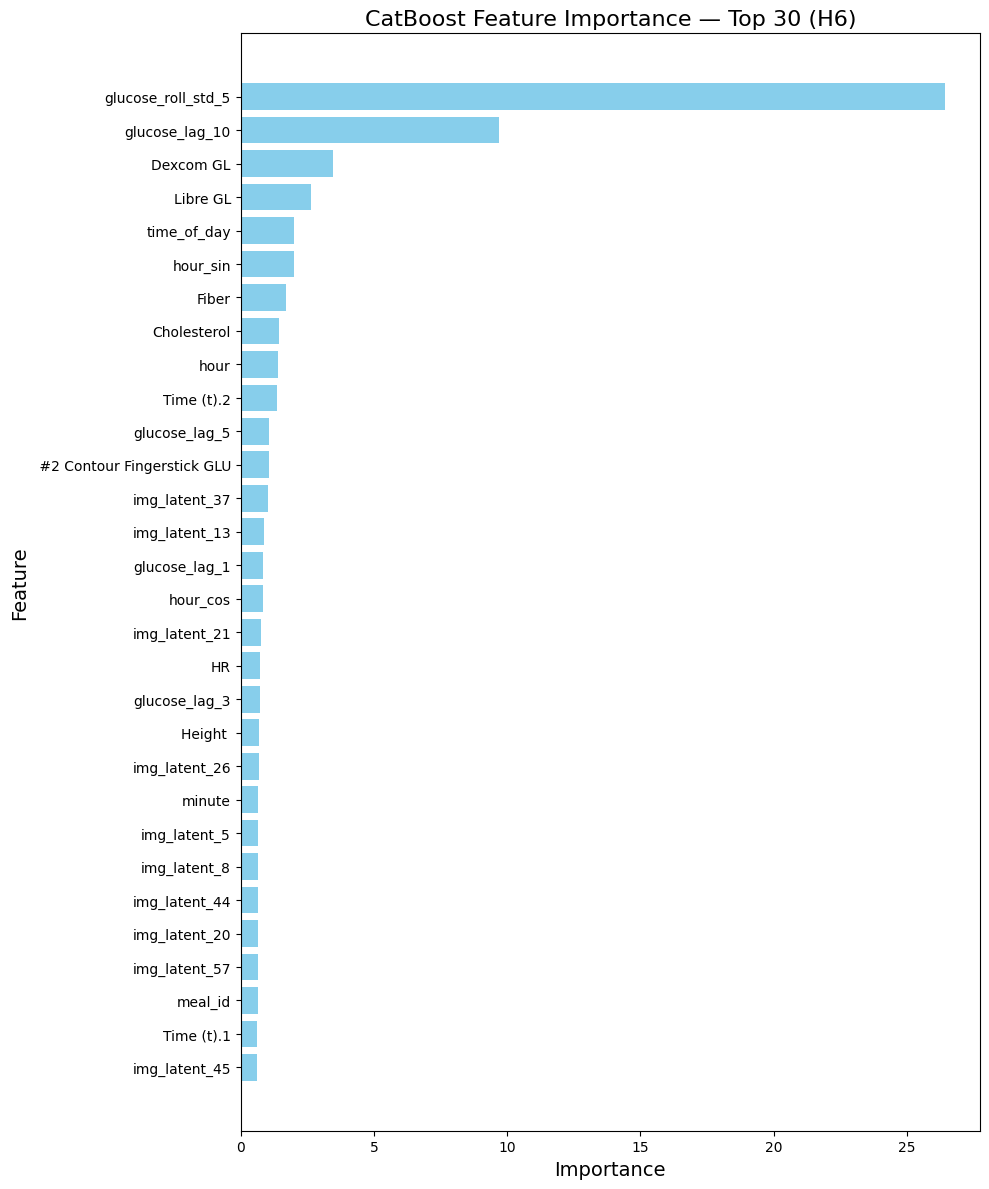

In [40]:
# ==============================================================================
# FEATURE IMPORTANCE — TOP 30 PER HORIZON (Bar Graph)
# ==============================================================================

import pandas as pd
import matplotlib.pyplot as plt

for horizon in HORIZONS:
    model = cat_models[horizon]
    importances = model.get_feature_importance()

    fi_df = pd.DataFrame({
        "feature": feature_cols,
        "importance": importances
    }).sort_values("importance", ascending=False).head(30)

    plt.figure(figsize=(10, 12))
    plt.barh(fi_df["feature"], fi_df["importance"], color="skyblue")
    plt.gca().invert_yaxis()

    plt.title(f"CatBoost Feature Importance — Top 30 ({horizon.upper()})", fontsize=16)
    plt.xlabel("Importance", fontsize=14)
    plt.ylabel("Feature", fontsize=14)

    plt.tight_layout()
    plt.show()


#LSTM

In [41]:
target_cols = ["glucose_delta_h1", "glucose_delta_h3", "glucose_delta_h6"]


In [42]:
df_model = processed_df.copy()

# Remove useless columns
df_model = df_model.drop(columns=["Unnamed: 0"], errors="ignore")

# Keep rows where ALL 3 targets exist
df_model = df_model.dropna(subset=target_cols)

# Features = all numeric except target + participant_id/meal_id
non_features = target_cols + ["participant_id", "meal_id"]
feature_cols = [
    c for c in df_model.columns
    if c not in non_features and pd.api.types.is_numeric_dtype(df_model[c])
]

# Fill NaNs in features
df_model[feature_cols] = df_model[feature_cols].fillna(0)
df_model = df_model.replace([np.inf, -np.inf], 0)

print("Dataset shape:", df_model.shape)
print("Num features:", len(feature_cols))


Dataset shape: (686820, 127)
Num features: 113


In [43]:
from sklearn.preprocessing import StandardScaler

scaled_dfs = []
scalers = {}

for pid, group in df_model.groupby("participant_id"):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(group[feature_cols])

    g = pd.DataFrame(X_scaled, columns=feature_cols, index=group.index)

    # Add all 3 targets
    for col in target_cols:
        g[col] = group[col].values

    g["participant_id"] = pid

    scaled_dfs.append(g)
    scalers[pid] = scaler

df_scaled = pd.concat(scaled_dfs).sort_values("participant_id").reset_index(drop=True)

print("Scaled dataset:", df_scaled.shape)


Scaled dataset: (686820, 117)


In [44]:
from sklearn.model_selection import GroupShuffleSplit

# First split: train vs temp (val+test)
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, temp_idx = next(gss1.split(df_scaled, groups=df_scaled["participant_id"]))

train_pids = df_scaled.iloc[train_idx]["participant_id"].unique()
temp_df = df_scaled.iloc[temp_idx]

# Second split: validation vs test
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["participant_id"]))

val_pids  = temp_df.iloc[val_idx]["participant_id"].unique()
test_pids = temp_df.iloc[test_idx]["participant_id"].unique()

train_df = df_scaled[df_scaled["participant_id"].isin(train_pids)]
val_df   = df_scaled[df_scaled["participant_id"].isin(val_pids)]
test_df  = df_scaled[df_scaled["participant_id"].isin(test_pids)]

print("Train:", train_df.shape)
print("Val  :", val_df.shape)
print("Test :", test_df.shape)


Train: (477089, 117)
Val  : (112373, 117)
Test : (97358, 117)


In [45]:
import torch
from torch.utils.data import Dataset, DataLoader

class MultiTargetSequenceDataset(Dataset):
    def __init__(self, df, seq_len, feature_cols, target_cols):
        self.seq_len = seq_len
        self.feature_cols = feature_cols
        self.target_cols = target_cols

        self.groups = []
        self.starts = []

        for pid, group in df.groupby("participant_id"):
            X = group[feature_cols].values
            Y = group[target_cols].values  # shape: [N, 3]

            n = len(group)
            if n <= seq_len:
                continue

            self.groups.append((X, Y))
            self.starts.append(np.arange(0, n - seq_len))

        self.global_indices = []
        for gi, starts in enumerate(self.starts):
            for s in starts:
                self.global_indices.append((gi, s))

    def __len__(self):
        return len(self.global_indices)

    def __getitem__(self, idx):
        gi, start = self.global_indices[idx]
        X, Y = self.groups[gi]

        seq = X[start : start + self.seq_len]
        target = Y[start + self.seq_len]   # (h1, h3, h6)

        return (
            torch.tensor(seq, dtype=torch.float32),
            torch.tensor(target, dtype=torch.float32)
        )


In [46]:
SEQ_LEN = 30
BATCH_SIZE = 128

train_dataset = MultiTargetSequenceDataset(train_df, SEQ_LEN, feature_cols, target_cols)
val_dataset   = MultiTargetSequenceDataset(val_df,   SEQ_LEN, feature_cols, target_cols)
test_dataset  = MultiTargetSequenceDataset(test_df,  SEQ_LEN, feature_cols, target_cols)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print("Train sequences:", len(train_dataset))
print("Val sequences:", len(val_dataset))
print("Test sequences:", len(test_dataset))


Train sequences: 476159
Val sequences: 112163
Test sequences: 97148


In [47]:
import torch.nn as nn

class MultiOutputLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=1, dropout=0.1):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 3)  # <-- output = 3 targets

    def forward(self, x):
        _, (hn, _) = self.lstm(x)
        out = self.fc(hn[-1])   # shape: [batch, 3]
        return out


In [48]:
import torch.optim as optim
from torch.cuda.amp import autocast, GradScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = MultiOutputLSTM(input_size=len(feature_cols)).to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scaler = GradScaler(enabled=(device.type == "cuda"))

EPOCHS = 10

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        with autocast(enabled=(device.type == "cuda")):
            preds = model(xb)      # shape [B, 3]
            loss = criterion(preds, yb)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

    train_loss /= len(train_loader)
    print(f"Epoch {epoch+1}/{EPOCHS}  Train Loss: {train_loss:.4f}")


Device: cpu
Epoch 1/10  Train Loss: 2.8928
Epoch 2/10  Train Loss: 2.2050
Epoch 3/10  Train Loss: 1.9995
Epoch 4/10  Train Loss: 1.8732
Epoch 5/10  Train Loss: 1.7909
Epoch 6/10  Train Loss: 1.7156
Epoch 7/10  Train Loss: 1.6572
Epoch 8/10  Train Loss: 1.6075
Epoch 9/10  Train Loss: 1.5589
Epoch 10/10  Train Loss: 1.5138


In [49]:
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from tqdm import tqdm

# ---- sMAPE FUNCTION ----
def smape(y_true, y_pred):
    return 100 * np.mean(
        2 * np.abs(y_pred - y_true) /
        (np.abs(y_true) + np.abs(y_pred) + 1e-8)
    )

model.eval()

y_true_val = []
y_pred_val = []

with torch.no_grad():
    for xb, yb in tqdm(val_loader, desc="Validation Evaluation"):
        xb = xb.to(device)
        preds = model(xb).cpu().numpy()

        y_pred_val.append(preds)
        y_true_val.append(yb.numpy())

y_true_val = np.concatenate(y_true_val, axis=0)   # shape: [N, 3]
y_pred_val = np.concatenate(y_pred_val, axis=0)   # shape: [N, 3]

# ---- Compute metrics for each of the 3 targets ----
val_metric_results = {}

for i, name in enumerate(target_cols):
    yt = y_true_val[:, i]
    yp = y_pred_val[:, i]

    r2_val   = r2_score(yt, yp)
    rmse_val = np.sqrt(mean_squared_error(yt, yp))
    mae_val  = mean_absolute_error(yt, yp)
    smape_val = smape(yt, yp)

    val_metric_results[name] = {
        "R2": r2_val,
        "RMSE": rmse_val,
        "MAE": mae_val,
        "sMAPE %": smape_val
    }

val_metric_results




Validation Evaluation: 100%|██████████| 877/877 [00:21<00:00, 41.03it/s]


{'glucose_delta_h1': {'R2': 0.6458395719528198,
  'RMSE': np.float64(0.34724876010994743),
  'MAE': 0.20963171124458313,
  'sMAPE %': np.float32(90.39801)},
 'glucose_delta_h3': {'R2': 0.6458094120025635,
  'RMSE': np.float64(1.0290922073631172),
  'MAE': 0.6292423605918884,
  'sMAPE %': np.float32(91.98519)},
 'glucose_delta_h6': {'R2': 0.6337544322013855,
  'RMSE': np.float64(2.0617481364027483),
  'MAE': 1.2839586734771729,
  'sMAPE %': np.float32(94.44267)}}

In [50]:
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from tqdm import tqdm

# ---- sMAPE FUNCTION ----
def smape(y_true, y_pred):
    return 100 * np.mean(
        2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)
    )

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for xb, yb in tqdm(test_loader, desc="Full Test Evaluation"):
        xb = xb.to(device)
        preds = model(xb).cpu().numpy()

        y_pred.append(preds)
        y_true.append(yb.numpy())

y_true = np.concatenate(y_true, axis=0)   # shape: [N, 3]
y_pred = np.concatenate(y_pred, axis=0)   # shape: [N, 3]

# ---- Compute metrics for each target ----
metric_results = {}
for i, name in enumerate(target_cols):
    yt = y_true[:, i]
    yp = y_pred[:, i]

    r2_val   = r2_score(yt, yp)
    rmse_val = np.sqrt(mean_squared_error(yt, yp))
    mae_val  = mean_absolute_error(yt, yp)
    smape_val = smape(yt, yp)

    metric_results[name] = {
        "R2": r2_val,
        "RMSE": rmse_val,
        "MAE": mae_val,
        "sMAPE %": smape_val
    }

metric_results


Full Test Evaluation: 100%|██████████| 759/759 [00:15<00:00, 48.84it/s]


{'glucose_delta_h1': {'R2': 0.6784814596176147,
  'RMSE': np.float64(0.3930834843497316),
  'MAE': 0.22947654128074646,
  'sMAPE %': np.float32(90.12106)},
 'glucose_delta_h3': {'R2': 0.6753722429275513,
  'RMSE': np.float64(1.1703914661530492),
  'MAE': 0.69016432762146,
  'sMAPE %': np.float32(91.97164)},
 'glucose_delta_h6': {'R2': 0.6630855798721313,
  'RMSE': np.float64(2.349035280127554),
  'MAE': 1.404826283454895,
  'sMAPE %': np.float32(94.3848)}}

In [51]:
import pandas as pd

# Convert both dictionaries into DataFrames
val_df = pd.DataFrame(val_metric_results).T
test_df = pd.DataFrame(metric_results).T

# Rename index to something nicer
val_df.index.name = "Target"
test_df.index.name = "Target"

print("=== VALIDATION PERFORMANCE ===")
display(val_df)

print("\n=== TEST PERFORMANCE ===")
display(test_df)


=== VALIDATION PERFORMANCE ===


,R2,RMSE,MAE,sMAPE %
Target,,,,
glucose_delta_h1,0.645840,0.347249,0.209632,90.398010
glucose_delta_h3,0.645809,1.029092,0.629242,91.985191
glucose_delta_h6,0.633754,2.061748,1.283959,94.442673



=== TEST PERFORMANCE ===


,R2,RMSE,MAE,sMAPE %
Target,,,,
glucose_delta_h1,0.678481,0.393083,0.229477,90.121063
glucose_delta_h3,0.675372,1.170391,0.690164,91.971642
glucose_delta_h6,0.663086,2.349035,1.404826,94.384804


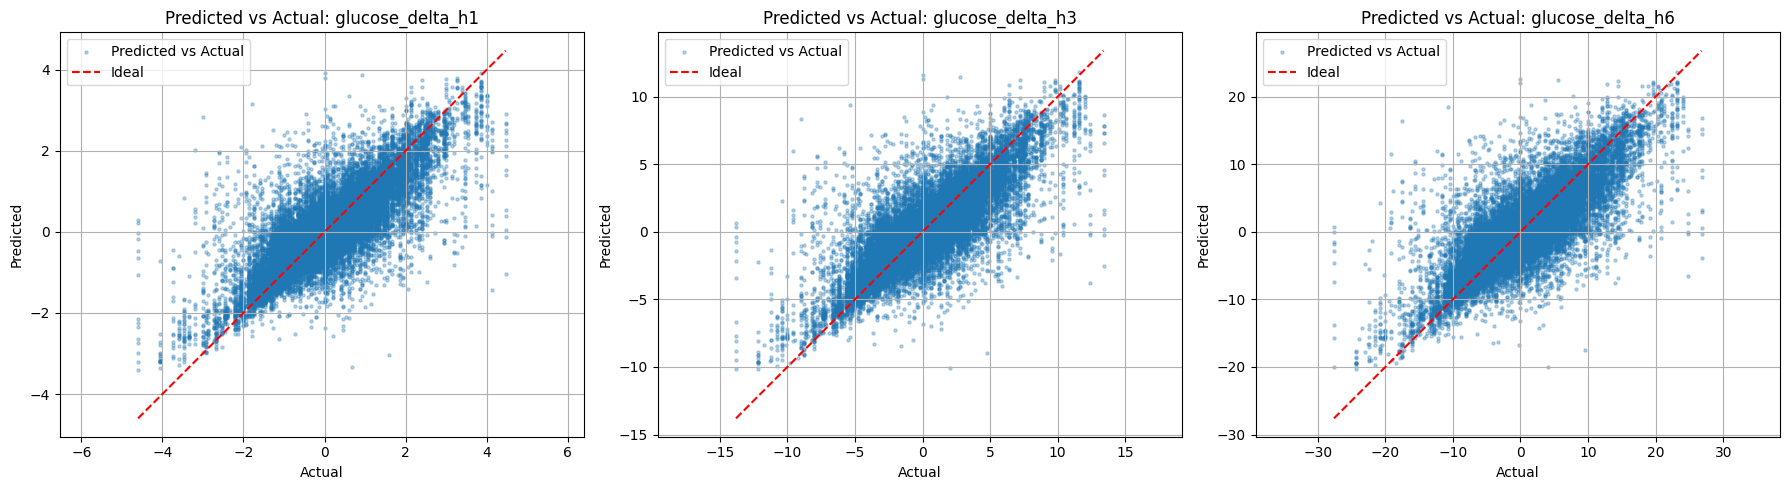

In [52]:
import matplotlib.pyplot as plt
import numpy as np

# y_true and y_pred already computed in your full test evaluation step
# shapes: [N, 3]

plt.figure(figsize=(18, 5))

for i, name in enumerate(target_cols):
    yt = y_true[:, i]
    yp = y_pred[:, i]

    plt.subplot(1, 3, i+1)
    plt.scatter(yt, yp, s=5, alpha=0.3, label="Predicted vs Actual")

    # perfect prediction line
    min_val = min(yt.min(), yp.min())
    max_val = max(yt.max(), yp.max())
    plt.plot([min_val, max_val], [min_val, max_val], "r--", label="Ideal")

    plt.title(f"Predicted vs Actual: {name}")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.legend()
    plt.grid(True)
    plt.axis("equal")  # keep scale equal for interpretation

plt.tight_layout()
plt.show()


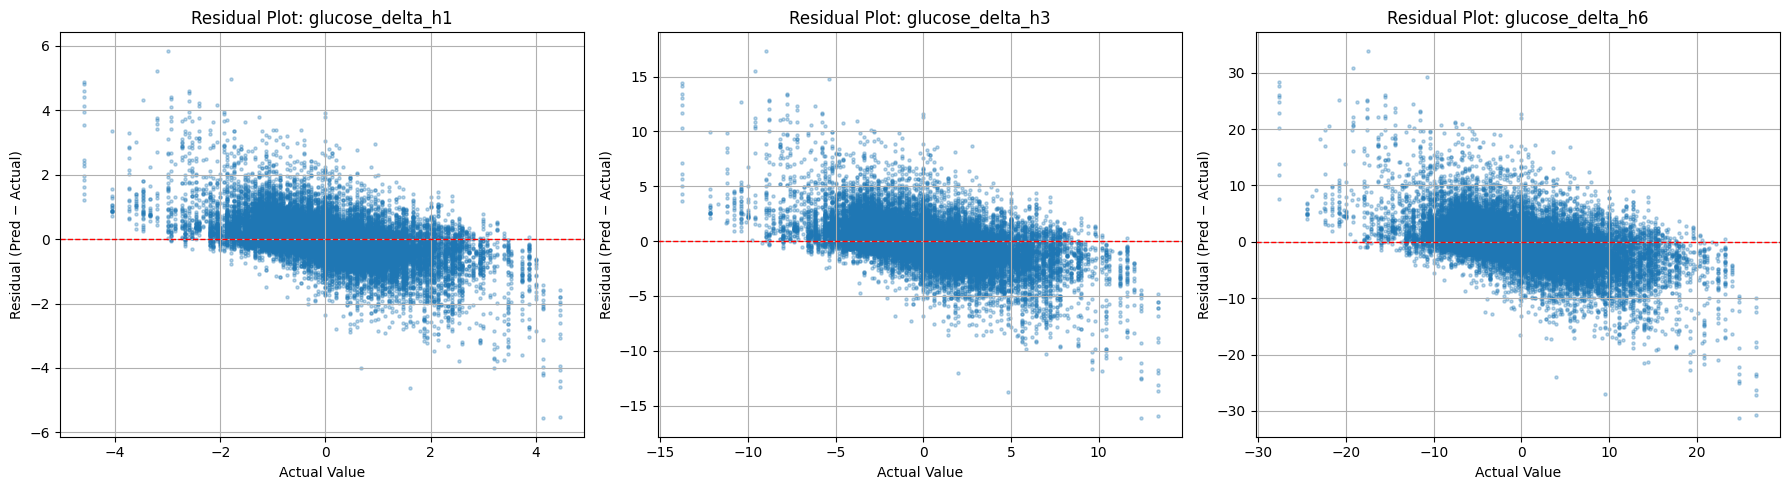

In [53]:
import matplotlib.pyplot as plt
import numpy as np

# y_true, y_pred shape: [N, 3]

plt.figure(figsize=(18, 5))

for i, name in enumerate(target_cols):
    yt = y_true[:, i]
    yp = y_pred[:, i]
    residuals = yp - yt

    plt.subplot(1, 3, i+1)

    # Scatter residuals vs actual value
    plt.scatter(yt, residuals, s=5, alpha=0.3)

    # Zero-error reference line
    plt.axhline(0, color='red', linestyle='--', linewidth=1)

    plt.title(f"Residual Plot: {name}")
    plt.xlabel("Actual Value")
    plt.ylabel("Residual (Pred − Actual)")
    plt.grid(True)

plt.tight_layout()
plt.show()


#SHAP EXPLANATION FOR LSTM MODEL (H1, H3, H6)


================ SHAP ANALYSIS FOR LSTM MODEL ================




----- SHAP Analysis for glucose_delta_h1 -----



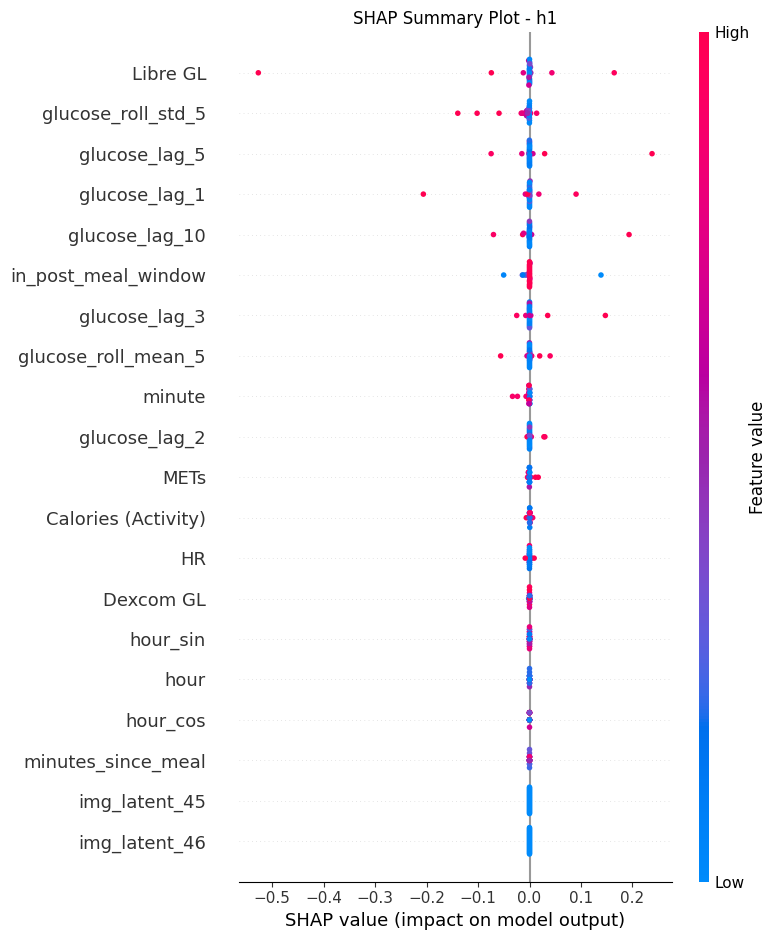

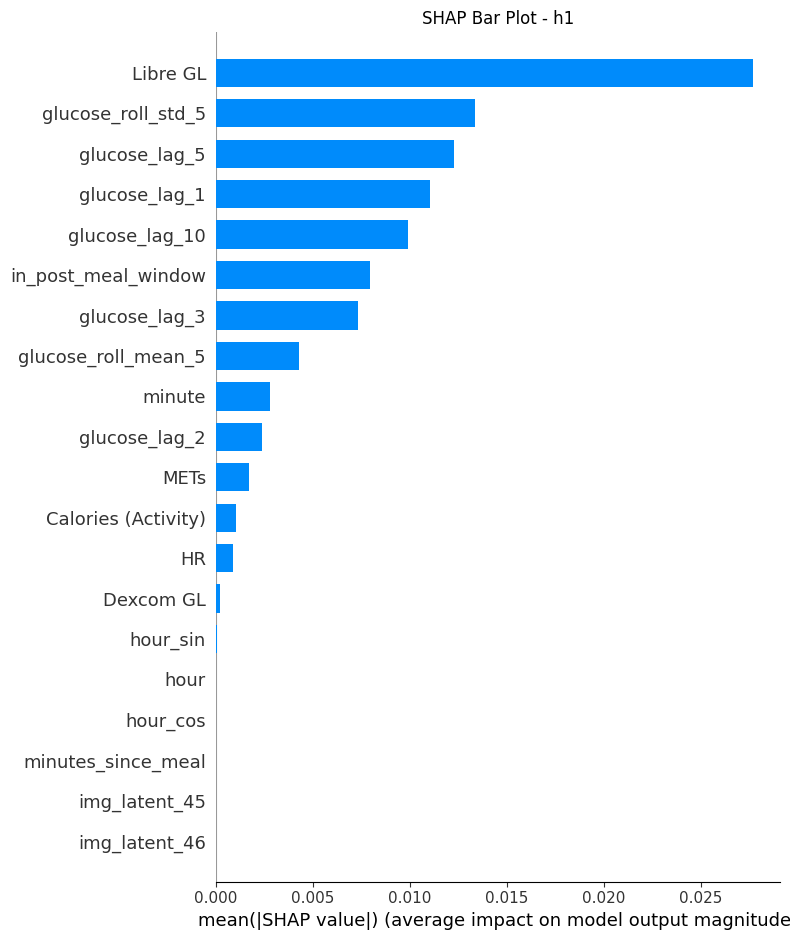

Top feature for h1: Libre GL


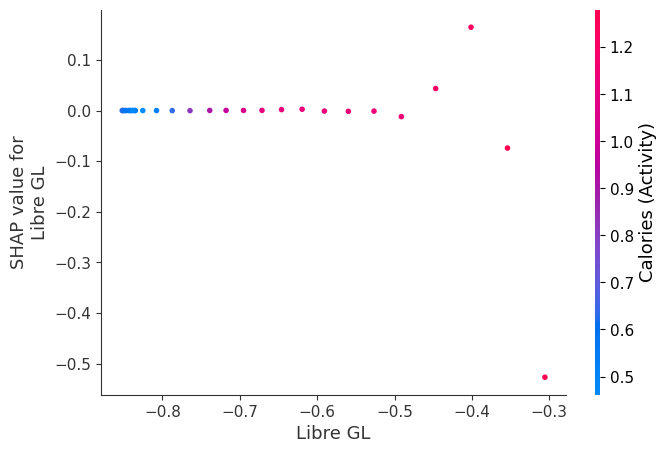


----- SHAP Analysis for glucose_delta_h3 -----



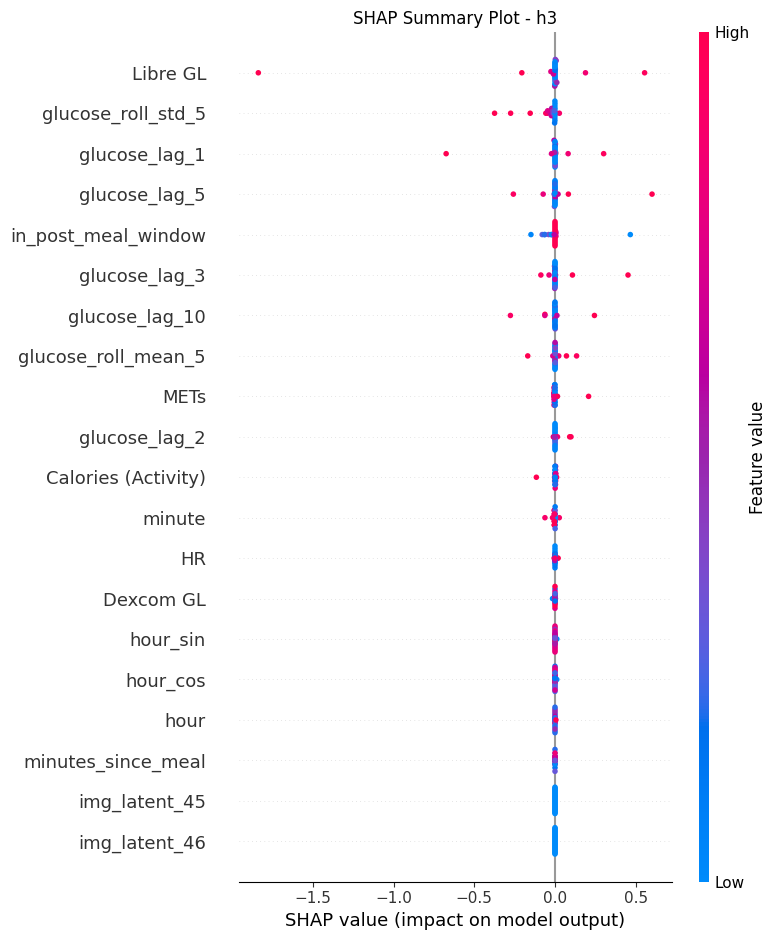

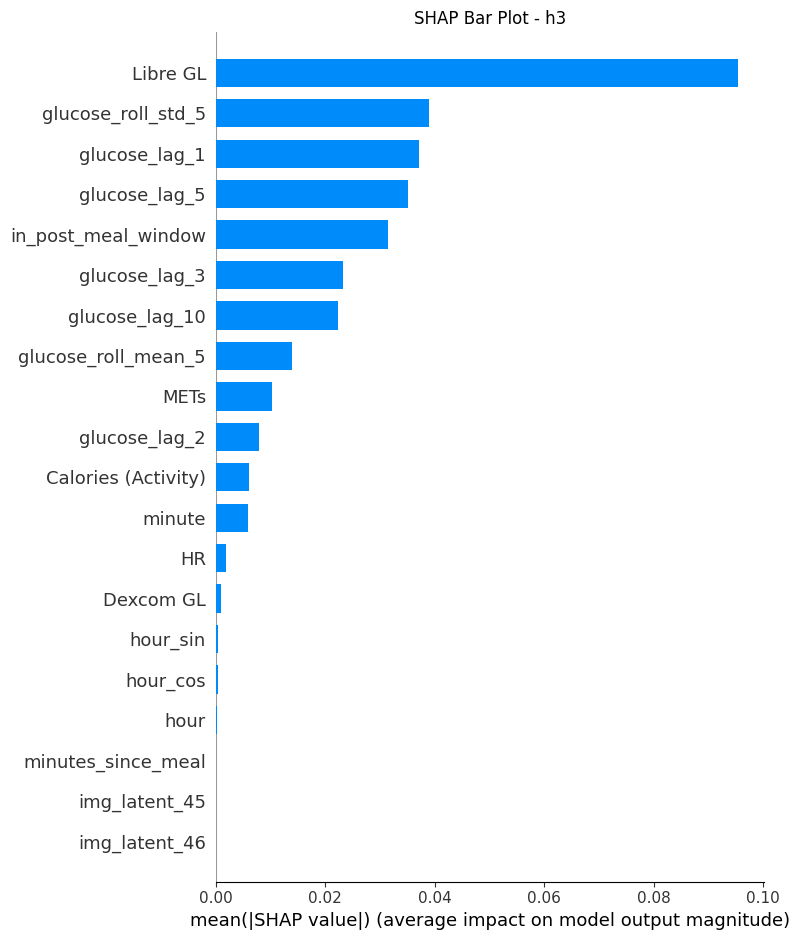

Top feature for h3: Libre GL


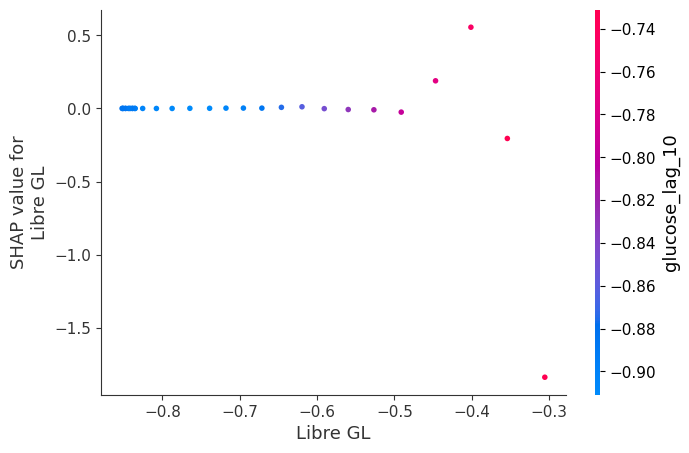


----- SHAP Analysis for glucose_delta_h6 -----



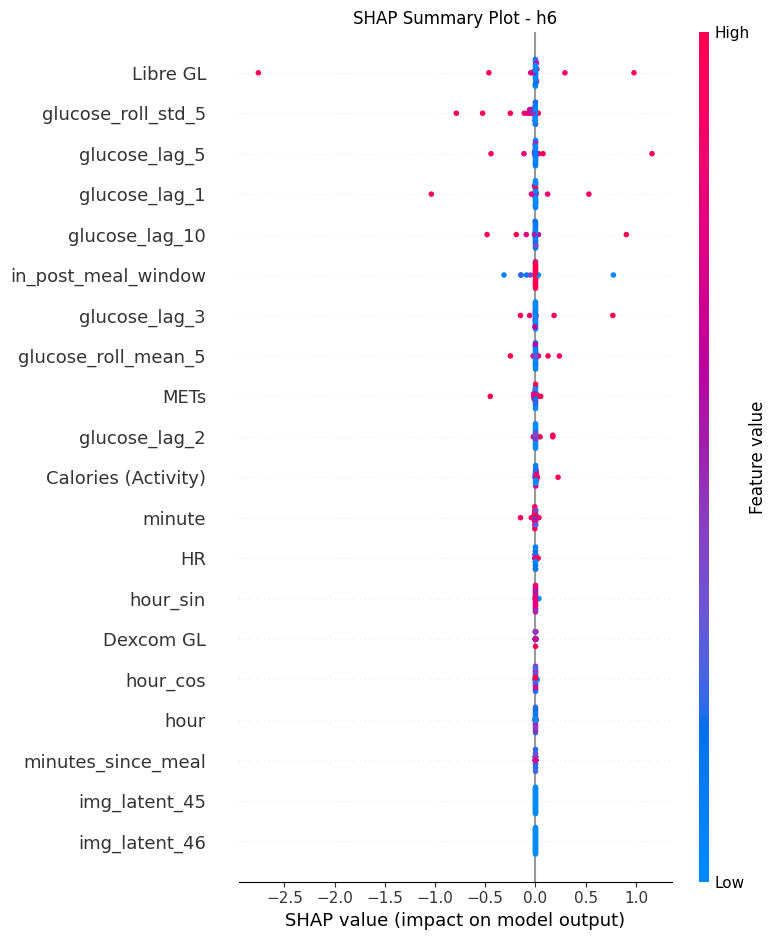

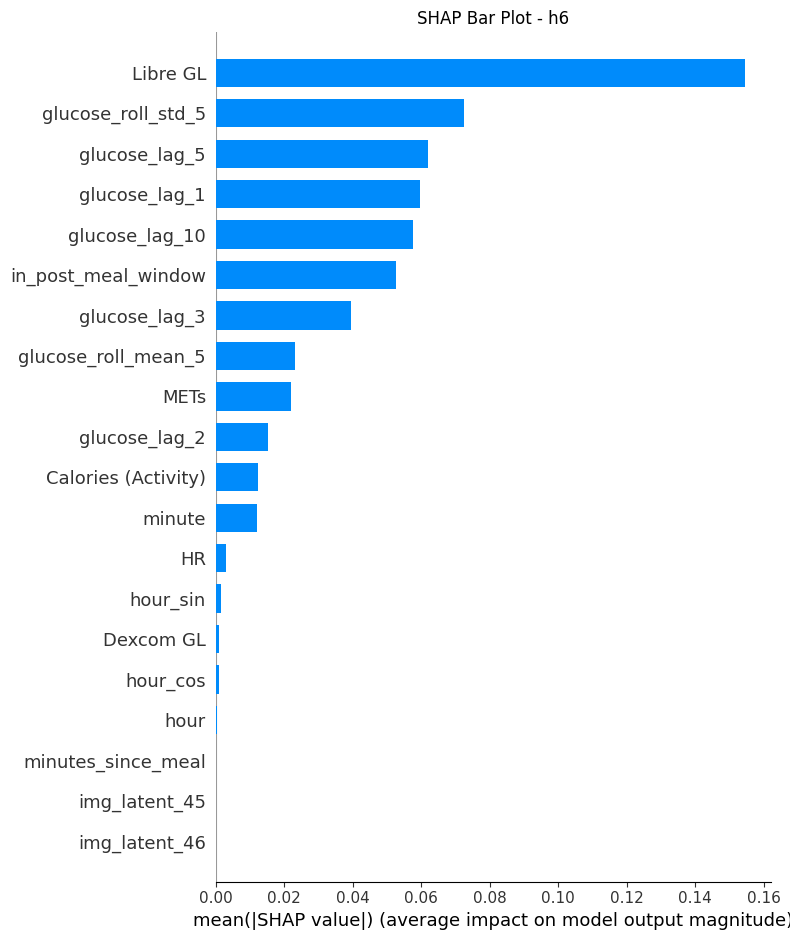

Top feature for h6: Libre GL


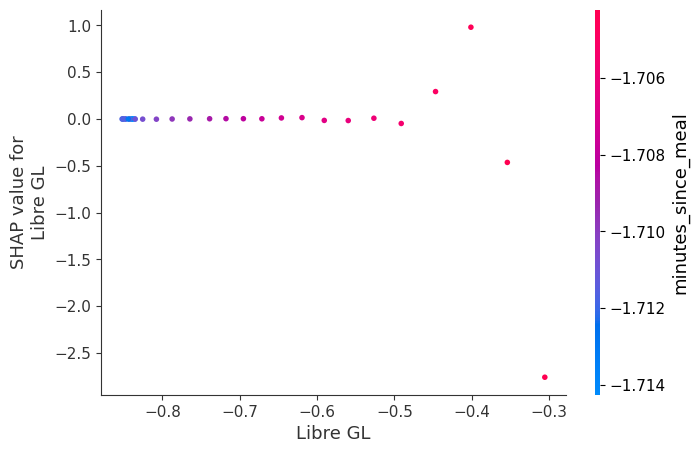


================ SHAP ANALYSIS COMPLETE ================



In [54]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

print("\n================ SHAP ANALYSIS FOR LSTM MODEL ================\n")

model.eval()

# 1. Build test batch (first 30 samples for SHAP)
#
NUM_SAMPLES = 30

for xb, yb in test_loader:
    xb_batch = xb[:NUM_SAMPLES].to(device)     # shape [30, seq_len, features]
    break

SEQ_LEN = xb_batch.shape[1]

# Flatten sequence → mean for each sample
X_test_flat = xb_batch.mean(dim=1).cpu().numpy()
X_test_df = pd.DataFrame(X_test_flat, columns=feature_cols)

shap.initjs()

# 2. GradientSHAP Explainer
explainer = shap.GradientExplainer(model, xb_batch)

# Raw SHAP values: (30, 113, 3)
shap_raw = explainer.shap_values(xb_batch)

# 3. Extract per-output SHAP in correct shape
HORIZONS = ["h1", "h3", "h6"]

# shap_raw[i] = (samples, features, outputs)
# We want: shap_vals = (samples, features) for output i

shap_fixed = []
for i in range(3):
    shap_fixed.append(shap_raw[i][:, :, i])   # take output i from last dim

# Now shap_fixed[i] has shape: (30, 113)


# 4. Plot SHAP for each horizon

for i, horizon in enumerate(HORIZONS):

    print(f"\n----- SHAP Analysis for glucose_delta_{horizon} -----\n")

    shap_vals = shap_fixed[i]     # (30, 113)

    # ========================== SUMMARY PLOT ==========================
    plt.title(f"SHAP Summary Plot - {horizon}")
    shap.summary_plot(shap_vals, X_test_df, feature_names=feature_cols, show=True)

    # ========================== BAR PLOT ==============================
    plt.title(f"SHAP Bar Plot - {horizon}")
    shap.summary_plot(shap_vals, X_test_df, feature_names=feature_cols,
                      plot_type="bar", show=True)

    # ======================= DEPENDENCE PLOT ==========================
    mean_abs_shap = np.abs(shap_vals).mean(axis=0)
    top_feature = feature_cols[np.argmax(mean_abs_shap)]

    print(f"Top feature for {horizon}: {top_feature}")

    shap.dependence_plot(top_feature, shap_vals, X_test_df, show=True)


print("\n================ SHAP ANALYSIS COMPLETE ================\n")


In [55]:
class TinyTransformer(nn.Module):
    def __init__(self, input_size, num_outputs=3):
        super().__init__()

        self.d_model = 32
        self.proj = nn.Linear(input_size, self.d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=self.d_model,
            nhead=2,
            dim_feedforward=64,
            dropout=0.1,
            batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)

        self.fc = nn.Linear(self.d_model, num_outputs)

    def forward(self, x):
        x = self.proj(x)         # [B, T, 32]
        x = self.encoder(x)      # [B, T, 32]
        x = x.mean(dim=1)        # global average pooling
        return self.fc(x)


In [56]:
BATCH_SIZE = 16
shuffle=False
num_workers=0
pin_memory=False
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


In [57]:
EPOCHS = 5

for epoch in range(EPOCHS):
    model.train()
    total = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()

        total += loss.item()

    print(f"Epoch {epoch+1} Loss: {total/len(train_loader):.4f}")


Epoch 1 Loss: 1.8243
Epoch 2 Loss: 1.7456
Epoch 3 Loss: 1.6859
Epoch 4 Loss: 1.6637
Epoch 5 Loss: 1.6221


In [58]:
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from tqdm import tqdm

def smape(y_true, y_pred):
    return 100 * np.mean(
        2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)
    )

model.eval()
y_true_list, y_pred_list = [], []

with torch.no_grad():
    for xb, yb in tqdm(test_loader, desc="Test Evaluation"):
        xb = xb.to(device)
        preds = model(xb).cpu().numpy()
        y_pred_list.append(preds)
        y_true_list.append(yb.numpy())

y_true = np.concatenate(y_true_list, axis=0)   # [N, 3]
y_pred = np.concatenate(y_pred_list, axis=0)   # [N, 3]

metric_results = {}

for i, name in enumerate(target_cols):
    yt = y_true[:, i]
    yp = y_pred[:, i]

    r2   = r2_score(yt, yp)
    rmse = np.sqrt(mean_squared_error(yt, yp))
    mae  = mean_absolute_error(yt, yp)
    s_m  = smape(yt, yp)

    metric_results[name] = {
        "R2": round(r2, 4),
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "sMAPE %": round(s_m, 4),
    }

metric_results


Test Evaluation: 100%|██████████| 6072/6072 [00:18<00:00, 328.60it/s]


{'glucose_delta_h1': {'R2': 0.6706,
  'RMSE': np.float64(0.3979),
  'MAE': 0.2355,
  'sMAPE %': np.float32(92.054)},
 'glucose_delta_h3': {'R2': 0.6668,
  'RMSE': np.float64(1.1858),
  'MAE': 0.7145,
  'sMAPE %': np.float32(93.8975)},
 'glucose_delta_h6': {'R2': 0.6535,
  'RMSE': np.float64(2.3821),
  'MAE': 1.4669,
  'sMAPE %': np.float32(96.7875)}}

In [59]:
import pandas as pd
pd.DataFrame(metric_results).T


,R2,RMSE,MAE,sMAPE %
glucose_delta_h1,0.6706,0.3979,0.2355,92.054001
glucose_delta_h3,0.6668,1.1858,0.7145,93.897499
glucose_delta_h6,0.6535,2.3821,1.4669,96.787498


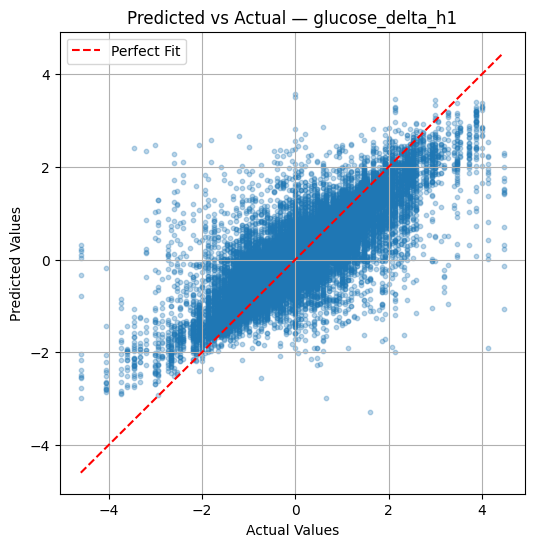

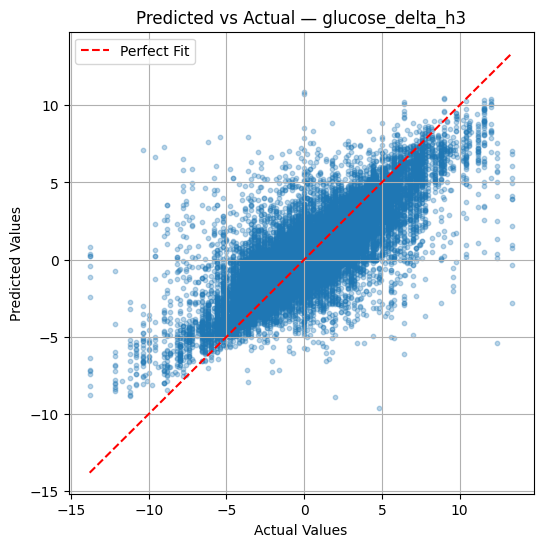

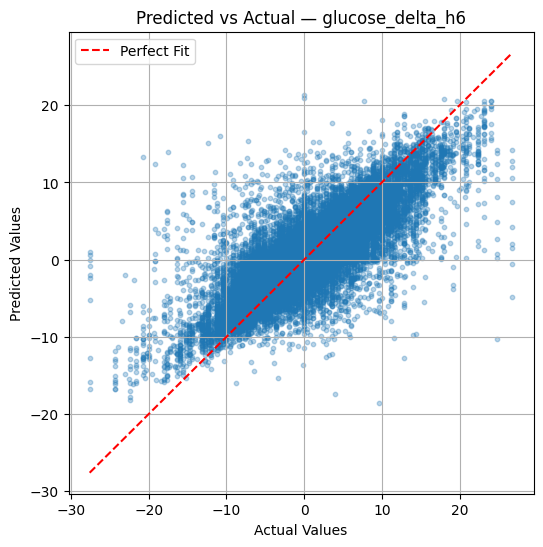

In [60]:
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

# COLLECT PREDICTIONS
model.eval()
y_true_list = []
y_pred_list = []

with torch.no_grad():
    for xb, yb in tqdm(test_loader, desc="Collecting Predictions"):
        xb = xb.to(device)
        preds = model(xb).cpu().numpy()
        y_pred_list.append(preds)
        y_true_list.append(yb.numpy())

y_true = np.concatenate(y_true_list, axis=0)   # [N, 3]
y_pred = np.concatenate(y_pred_list, axis=0)   # [N, 3]


# -----------------------------
# PLOTTING FUNCTION
# -----------------------------
def plot_pred_vs_actual(y_true, y_pred, title):
    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.3, s=10)
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(title)

    # Add perfect prediction line
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', label="Perfect Fit")

    plt.legend()
    plt.grid(True)
    plt.show()


# -----------------------------
# GENERATE PLOTS FOR ALL TARGETS
# -----------------------------
for i, name in enumerate(target_cols):
    plot_pred_vs_actual(
        y_true[:, i],
        y_pred[:, i],
        f"Predicted vs Actual — {name}"
    )


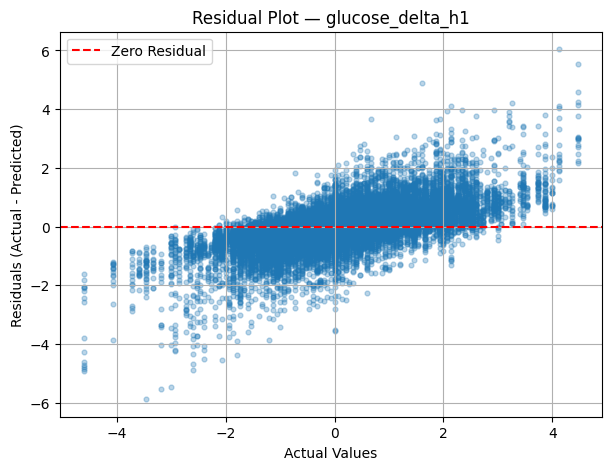

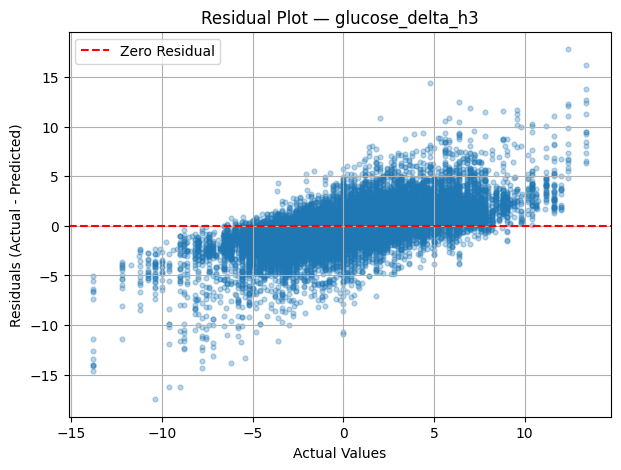

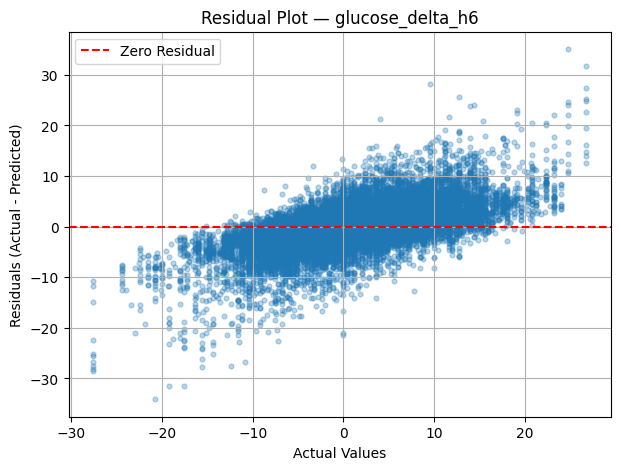

In [61]:
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

# COLLECT PREDICTIONS
model.eval()
y_true_list = []
y_pred_list = []

with torch.no_grad():
    for xb, yb in tqdm(test_loader, desc="Collecting predictions for residuals"):
        xb = xb.to(device)
        preds = model(xb).cpu().numpy()
        y_pred_list.append(preds)
        y_true_list.append(yb.numpy())

y_true = np.concatenate(y_true_list, axis=0)   # [N, 3]
y_pred = np.concatenate(y_pred_list, axis=0)   # [N, 3]

# RESIDUALS = Actual - Predicted
residuals = y_true - y_pred   # [N, 3]


# PLOTTING FUNCTION
def plot_residuals(y_true, residuals, title):
    plt.figure(figsize=(7, 5))

    plt.scatter(y_true, residuals, alpha=0.3, s=12)
    plt.axhline(0, color='red', linestyle='--', label="Zero Residual")

    plt.xlabel("Actual Values")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.title(title)

    plt.grid(True)
    plt.legend()
    plt.show()


# GENERATE RESIDUAL PLOTS
for i, name in enumerate(target_cols):
    plot_residuals(
        y_true[:, i],
        residuals[:, i],
        f"Residual Plot — {name}"
    )


# SHAP-LIKE ANALYSIS FOR TRANSFORMER


================ SHAP-LIKE ANALYSIS FOR TRANSFORMER MODEL ================




----- SHAP Analysis for glucose_delta_h1 -----



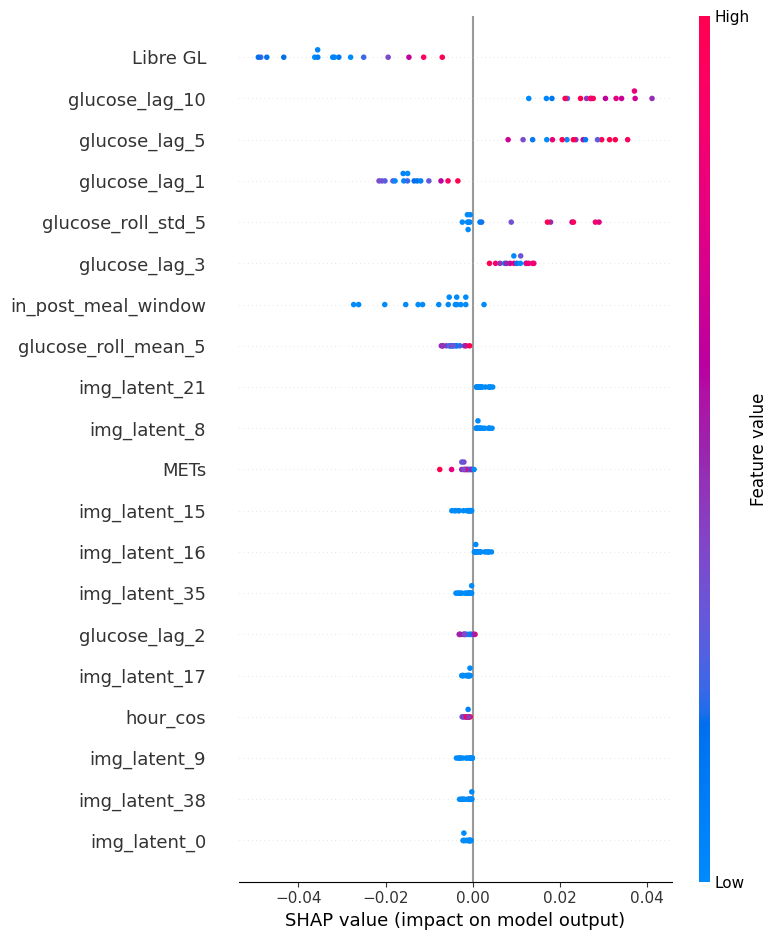

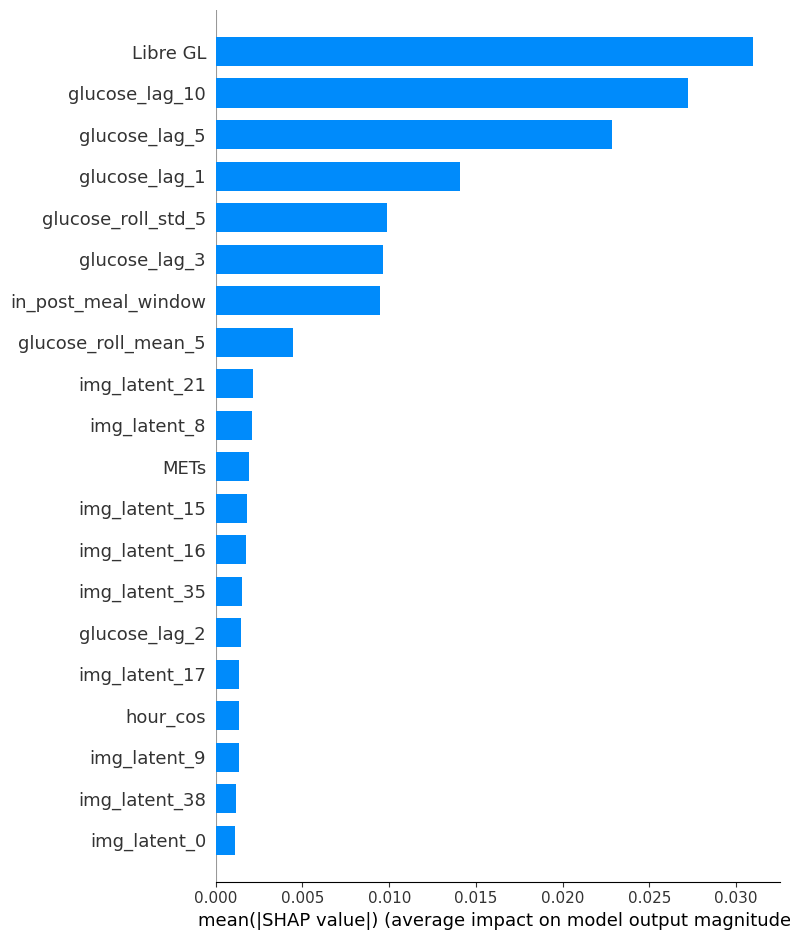

Top feature for h1 : Libre GL


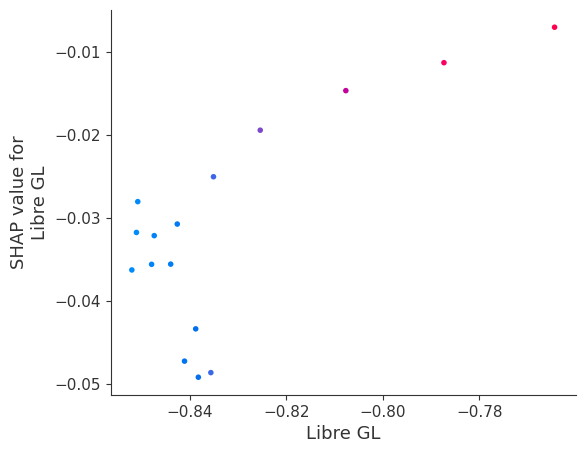


----- SHAP Analysis for glucose_delta_h3 -----



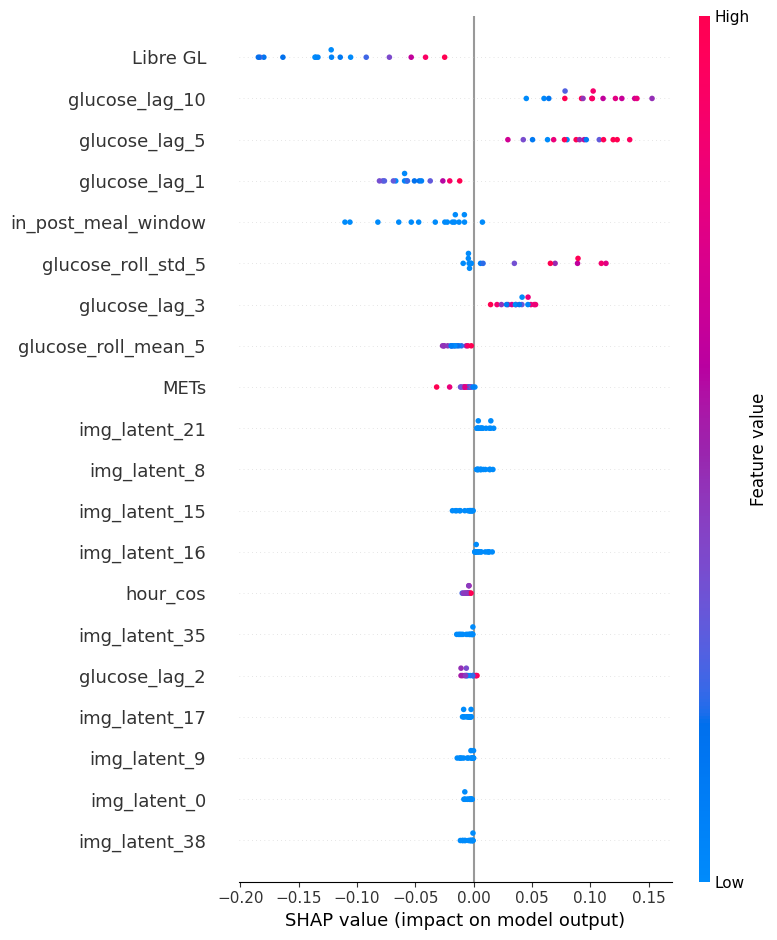

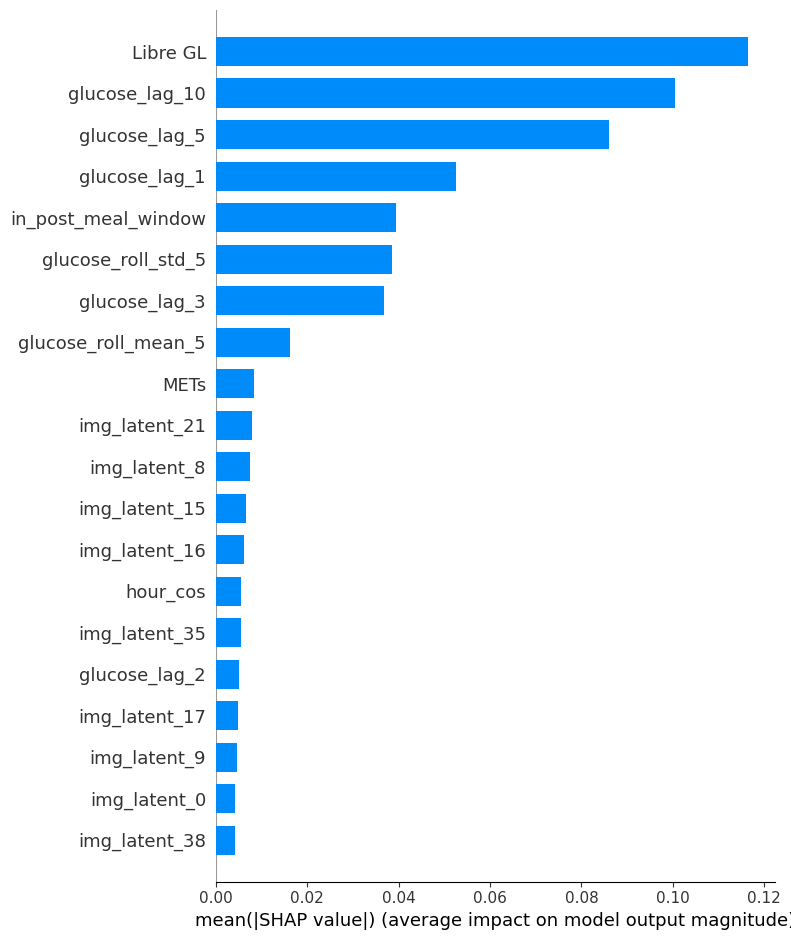

Top feature for h3 : Libre GL


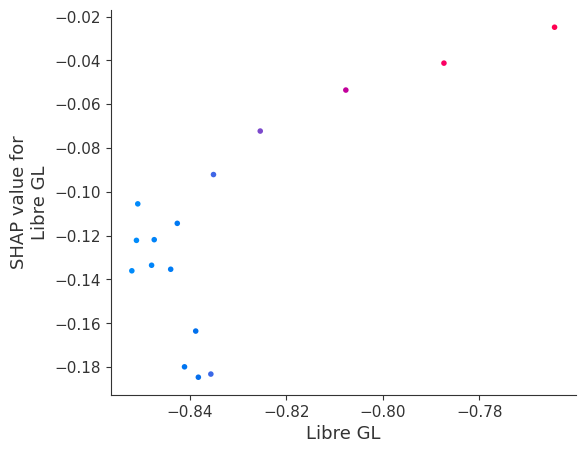


----- SHAP Analysis for glucose_delta_h6 -----



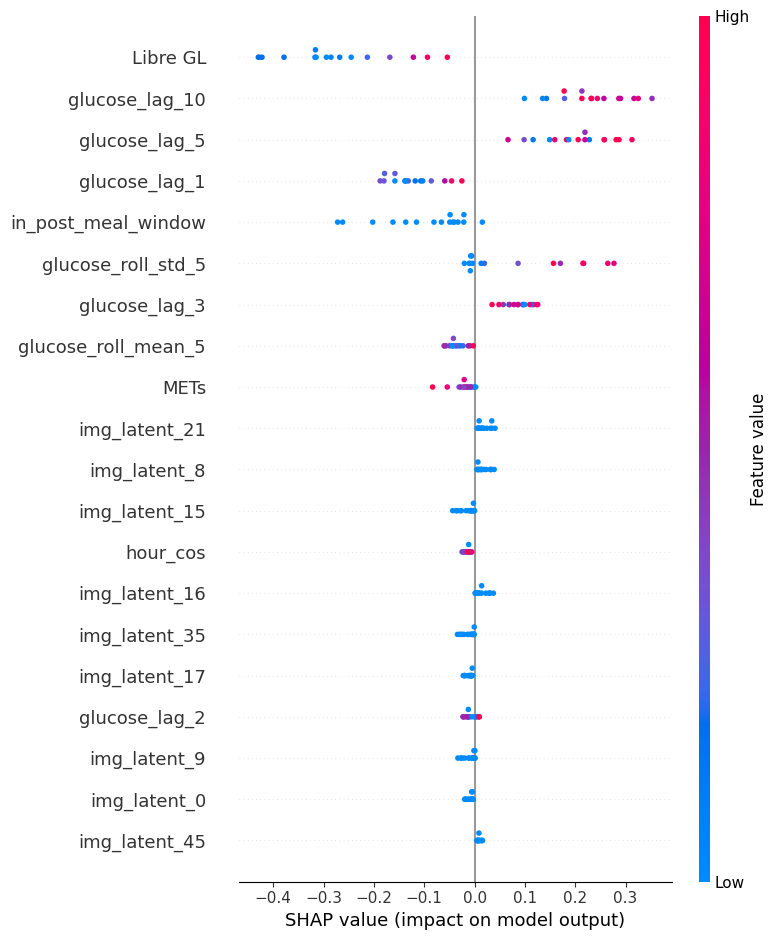

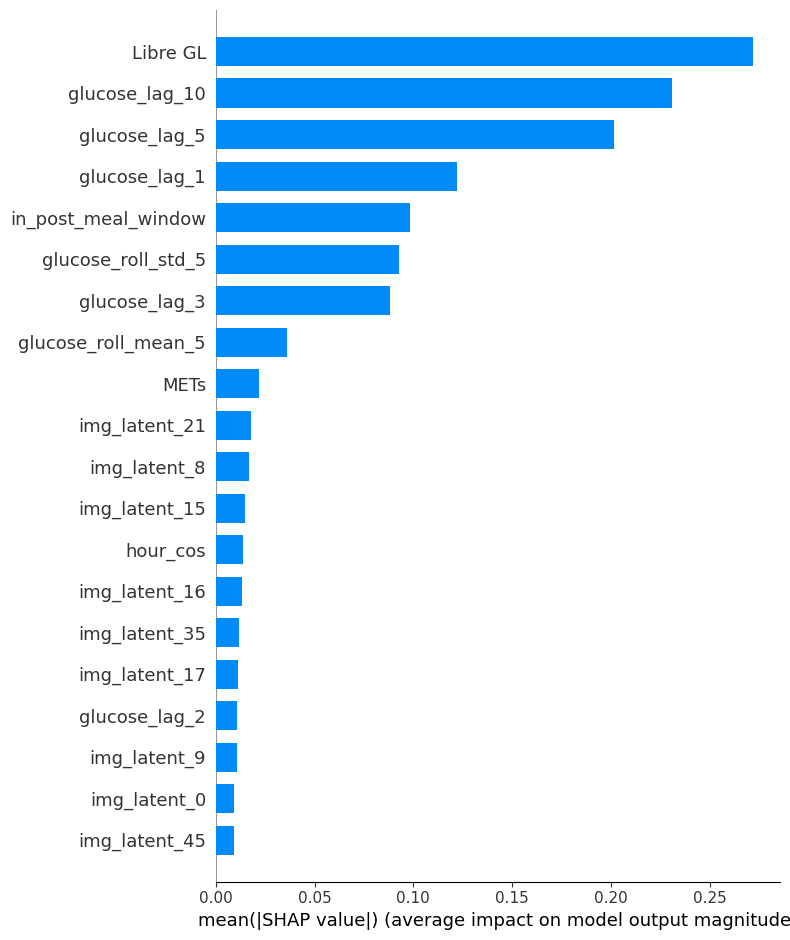

Top feature for h6 : Libre GL


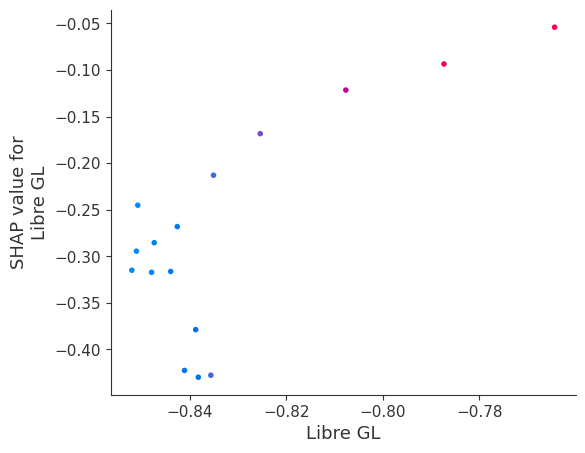


================ SHAP-LIKE ANALYSIS COMPLETE ================



In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import torch

print("\n================ SHAP-LIKE ANALYSIS FOR TRANSFORMER MODEL ================\n")

model.eval()

# 1. Take first batch from test_loader
for xb, yb in test_loader:
    xb_batch = xb.to(device)
    break

BATCH = xb_batch.shape[0]    # <-- REAL batch size (e.g., 16)
SEQ = xb_batch.shape[1]
FEAT = xb_batch.shape[2]

# Convert input to DataFrame (mean pooled)
X_test_flat = xb_batch.mean(dim=1).detach().cpu().numpy()
X_test_df = pd.DataFrame(X_test_flat, columns=feature_cols)

shap.initjs()

# 2. Compute GRAD × INPUT
xb_batch.requires_grad_(True)
outputs = model(xb_batch)   # shape (BATCH, 3)

shap_raw = []   # will mimic: shap_raw[i] → (BATCH, 113, 3)

HORIZONS = ["h1", "h3", "h6"]

for out_idx in range(3):

    model.zero_grad()
    loss = outputs[:, out_idx].sum()
    loss.backward(retain_graph=True)

    grads = xb_batch.grad.detach().cpu().numpy()       # (BATCH, seq_len, 113)
    inp   = xb_batch.detach().cpu().numpy()            # (BATCH, seq_len, 113)

    gx = grads * inp                                   # (BATCH, seq_len, 113)
    gx = gx.mean(axis=1)                                # (BATCH, 113)

    # Build SHAP matrix: (BATCH, 113, 3)
    gx_3 = np.zeros((BATCH, FEAT, 3))
    gx_3[:, :, out_idx] = gx                            # fill only this output

    shap_raw.append(gx_3)

# 3. Extract per-output feature importance: SHAP-compatible
shap_fixed = []
for i in range(3):
    shap_fixed.append(shap_raw[i][:, :, i])   # shape → (BATCH, 113)

# 4. IDENTICAL SHAP PLOTS as LSTM
for i, horizon in enumerate(HORIZONS):

    print(f"\n----- SHAP Analysis for glucose_delta_{horizon} -----\n")

    shap_vals = shap_fixed[i]   # (BATCH, 113)

    # SUMMARY PLOT
    shap.summary_plot(
        shap_vals,
        X_test_df,
        feature_names=feature_cols,
        show=True
    )

    # BAR PLOT
    shap.summary_plot(
        shap_vals,
        X_test_df,
        feature_names=feature_cols,
        plot_type="bar",
        show=True
    )

    # DEPENDENCE PLOT
    mean_abs_shap = np.abs(shap_vals).mean(axis=0)
    top_feature = feature_cols[np.argmax(mean_abs_shap)]
    print("Top feature for", horizon, ":", top_feature)

    shap.dependence_plot(
        top_feature,
        shap_vals,
        X_test_df,
        show=True
    )

print("\n================ SHAP-LIKE ANALYSIS COMPLETE ================\n")
